In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.impute import SimpleImputer
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score, GridSearchCV
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, roc_curve, average_precision_score,
    precision_recall_curve, confusion_matrix, classification_report
)
from sklearn.calibration import calibration_curve, CalibratedClassifierCV
import warnings
warnings.filterwarnings("ignore")

In [2]:
base = r"C:\Users\arjun\Desktop\College\3rd year(5th sem)\TRAINING 5TH SEM DATA SCIENCE\synthea-master\output\csv"

patients     = pd.read_csv(base + r"\patients.csv", parse_dates=["BIRTHDATE", "DEATHDATE"])
observations = pd.read_csv(base + r"\observations.csv", parse_dates=["DATE"])
conditions   = pd.read_csv(base + r"\conditions.csv", parse_dates=["START"])
encounters   = pd.read_csv(base + r"\encounters.csv", parse_dates=["START"])
medications  = pd.read_csv(base + r"\medications.csv", parse_dates=["START"])

In [3]:
patients.head()

,Id,BIRTHDATE,DEATHDATE,SSN,DRIVERS,PASSPORT,PREFIX,FIRST,MIDDLE,LAST,...,CITY,STATE,COUNTY,FIPS,ZIP,LAT,LON,HEALTHCARE_EXPENSES,HEALTHCARE_COVERAGE,INCOME
0,76b20010-c318-5754-8c85-983aa538522f,2018-03-15,NaT,999-62-9324,NaN,NaN,NaN,Jody426,Jeffrey461,Hickle134,...,Newburyport,Massachusetts,Essex County,25009.0,1950,42.813081,-70.838929,12926.22,10523.20,878354
1,2d68ad16-268a-478c-1f84-d0f1976e1a46,2020-02-17,NaT,999-71-2318,NaN,NaN,NaN,Mauro926,Isaias604,Braun514,...,Quincy,Massachusetts,Norfolk County,25021.0,2186,42.259372,-71.012584,11394.17,0.00,103247
2,aee7bbe1-0c45-c028-1e62-1f4cdb30c273,2010-12-19,NaT,999-21-5544,NaN,NaN,NaN,Wilfredo622,Isaiah615,Fritsch593,...,Whitman,Massachusetts,Plymouth County,NaN,0,42.095114,-70.967805,31849.63,130.67,102779
3,46976cf7-b0bf-be20-39a5-9f425a52886d,2007-09-10,NaT,999-37-5783,S99914003,NaN,Ms.,Lindsay928,Deja232,Zieme486,...,Worcester,Massachusetts,Worcester County,25027.0,1607,42.295897,-71.860710,55934.55,5543.16,95959
4,5e688e99-61b3-5c88-3f60-21df8aaced27,2010-01-24,NaT,999-87-5260,S99933561,NaN,NaN,Wallace647,Raymond398,Effertz744,...,Revere,Massachusetts,Suffolk County,25025.0,2151,42.425852,-70.948221,2671.02,57629.98,22038


In [4]:
patients.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5743 entries, 0 to 5742
Data columns (total 28 columns):
 #   Column               Non-Null Count  Dtype         
---  ------               --------------  -----         
 0   Id                   5743 non-null   object        
 1   BIRTHDATE            5743 non-null   datetime64[ns]
 2   DEATHDATE            743 non-null    datetime64[ns]
 3   SSN                  5743 non-null   object        
 4   DRIVERS              4761 non-null   object        
 5   PASSPORT             4484 non-null   object        
 6   PREFIX               4622 non-null   object        
 7   FIRST                5743 non-null   object        
 8   MIDDLE               4579 non-null   object        
 9   LAST                 5743 non-null   object        
 10  SUFFIX               55 non-null     object        
 11  MAIDEN               1607 non-null   object        
 12  MARITAL              3839 non-null   object        
 13  RACE                 5743 non-nul

In [5]:
patients.describe()

,BIRTHDATE,DEATHDATE,FIPS,ZIP,LAT,LON,HEALTHCARE_EXPENSES,HEALTHCARE_COVERAGE,INCOME
count,5743,743,4243.000000,5743.000000,5743.000000,5743.000000,5.743000e+03,5.743000e+03,5743.000000
mean,1982-04-06 03:03:17.457774720,2007-06-29 06:41:11.063257088,25088.503182,1463.945673,42.253302,-71.355941,1.848284e+05,3.326207e+05,117861.449765
min,1915-11-18 00:00:00,1934-02-22 00:00:00,25001.000000,0.000000,41.269627,-73.468820,1.000000e+02,0.000000e+00,40.000000
25%,1963-06-23 00:00:00,1999-06-19 12:00:00,25011.000000,0.000000,42.099835,-71.587436,2.347115e+04,1.885499e+04,34355.000000
50%,1982-07-18 00:00:00,2011-02-16 00:00:00,25017.000000,1851.000000,42.302662,-71.155671,9.721137e+04,1.432501e+05,70785.000000
75%,2003-08-13 00:00:00,2019-02-27 00:00:00,25025.000000,2151.000000,42.440745,-71.007114,2.274785e+05,5.343036e+05,127624.000000
max,2026-09-25 00:00:00,2026-09-04 00:00:00,44007.000000,2861.000000,42.894345,-69.925935,2.012980e+06,4.440999e+06,996720.000000
std,NaN,NaN,1164.101633,955.601172,0.290651,0.629705,2.429256e+05,4.463012e+05,170587.255454


In [6]:
patients.shape

(5743, 28)

In [7]:
patients.columns

Index(['Id', 'BIRTHDATE', 'DEATHDATE', 'SSN', 'DRIVERS', 'PASSPORT', 'PREFIX',
       'FIRST', 'MIDDLE', 'LAST', 'SUFFIX', 'MAIDEN', 'MARITAL', 'RACE',
       'ETHNICITY', 'GENDER', 'BIRTHPLACE', 'ADDRESS', 'CITY', 'STATE',
       'COUNTY', 'FIPS', 'ZIP', 'LAT', 'LON', 'HEALTHCARE_EXPENSES',
       'HEALTHCARE_COVERAGE', 'INCOME'],
      dtype='object')

In [8]:
patients['RACE'].unique()

array(['white', 'native', 'black', 'asian', 'other', 'hawaiian'],
      dtype=object)

In [9]:
patients['ETHNICITY'].unique()

array(['nonhispanic', 'hispanic'], dtype=object)

In [10]:
patients.RACE.value_counts()

RACE
white       4719
black        486
asian        360
other         77
hawaiian      65
native        36
Name: count, dtype: int64

In [11]:
patients.ETHNICITY.value_counts()

ETHNICITY
nonhispanic    5136
hispanic        607
Name: count, dtype: int64

In [12]:
for feature in patients.columns:
    if patients[feature].dtype=='object':
        print(patients[feature].value_counts())
        print('\n')

Id
bbbdcce6-ce73-56c0-c330-b3f4a9c7f5d8    1
76b20010-c318-5754-8c85-983aa538522f    1
2d68ad16-268a-478c-1f84-d0f1976e1a46    1
aee7bbe1-0c45-c028-1e62-1f4cdb30c273    1
46976cf7-b0bf-be20-39a5-9f425a52886d    1
                                       ..
c0a47dee-cc72-29ce-df5a-ea6d306c36a4    1
2c167999-289d-95fa-5c27-7d8b8d35348c    1
9661a432-4630-2cd9-142c-386845fae837    1
bff9d9d5-ee3d-d852-9c67-36d8361a4a4a    1
d15b23ed-02d5-3e28-efbd-2604425317c5    1
Name: count, Length: 5743, dtype: int64


SSN
999-90-8743    2
999-15-2205    2
999-91-7833    2
999-48-5810    2
999-55-3214    2
              ..
999-79-8860    1
999-98-3212    1
999-32-9004    1
999-47-1569    1
999-67-4540    1
Name: count, Length: 5727, dtype: int64


DRIVERS
S99995399    3
S99954064    3
S99933490    3
S99941836    2
S99978071    2
            ..
S99927009    1
S99999545    1
S99915654    1
S99931870    1
S99911108    1
Name: count, Length: 4629, dtype: int64


PASSPORT
X44189577X    1
X40961508X    1
X145

In [13]:
patients.isnull().sum()

Id                        0
BIRTHDATE                 0
DEATHDATE              5000
SSN                       0
DRIVERS                 982
PASSPORT               1259
PREFIX                 1121
FIRST                     0
MIDDLE                 1164
LAST                      0
SUFFIX                 5688
MAIDEN                 4136
MARITAL                1904
RACE                      0
ETHNICITY                 0
GENDER                    0
BIRTHPLACE                0
ADDRESS                   0
CITY                      0
STATE                     0
COUNTY                    0
FIPS                   1500
ZIP                       0
LAT                       0
LON                       0
HEALTHCARE_EXPENSES       0
HEALTHCARE_COVERAGE       0
INCOME                    0
dtype: int64

In [14]:
patients.duplicated().sum()

np.int64(0)

In [15]:
char = []
num = []
for feature in patients.columns:
    if patients[feature].dtype == 'object':
        char.append(feature)
    else:
        num.append(feature)

In [16]:
today = pd.Timestamp.today()

patients["AGE"] = np.where(
    patients["DEATHDATE"].isna(),                                    
    (today - patients["BIRTHDATE"]).dt.days / 365.25,                 
    (patients["DEATHDATE"] - patients["BIRTHDATE"]).dt.days / 365.25  
)

In [17]:
patients["DECEASED"] = patients["DEATHDATE"].notna()

In [18]:
patients_clean = patients[["Id", "BIRTHDATE", "DEATHDATE", "RACE", "ETHNICITY", "GENDER"]].copy()

patients_clean["DECEASED"] = patients_clean["DEATHDATE"].notna()

today = pd.Timestamp.today()
patients_clean["AGE"] = np.where(
    patients_clean["DEATHDATE"].isna(),
    (today - patients_clean["BIRTHDATE"]).dt.days / 365.25,
    (patients_clean["DEATHDATE"] - patients_clean["BIRTHDATE"]).dt.days / 365.25
)

patients_clean = patients_clean.rename(columns={"Id": "PATIENT"})  
patients_clean.head()

,PATIENT,BIRTHDATE,DEATHDATE,RACE,ETHNICITY,GENDER,DECEASED,AGE
0,76b20010-c318-5754-8c85-983aa538522f,2018-03-15,NaT,white,nonhispanic,M,False,8.547570
1,2d68ad16-268a-478c-1f84-d0f1976e1a46,2020-02-17,NaT,white,nonhispanic,M,False,6.620123
2,aee7bbe1-0c45-c028-1e62-1f4cdb30c273,2010-12-19,NaT,white,nonhispanic,M,False,15.783710
3,46976cf7-b0bf-be20-39a5-9f425a52886d,2007-09-10,NaT,white,nonhispanic,F,False,19.058179
4,5e688e99-61b3-5c88-3f60-21df8aaced27,2010-01-24,NaT,native,nonhispanic,M,False,16.684463


In [19]:
patients_clean["AGE"] = patients_clean["AGE"].astype(int)

In [20]:
patients_clean['AGE']

0         8
1         6
2        15
3        19
4        16
       ... 
5738      1
5739     83
5740     75
5741     73
5742    107
Name: AGE, Length: 5743, dtype: int64

In [21]:
print(patients_clean["AGE"].isna().sum())

0


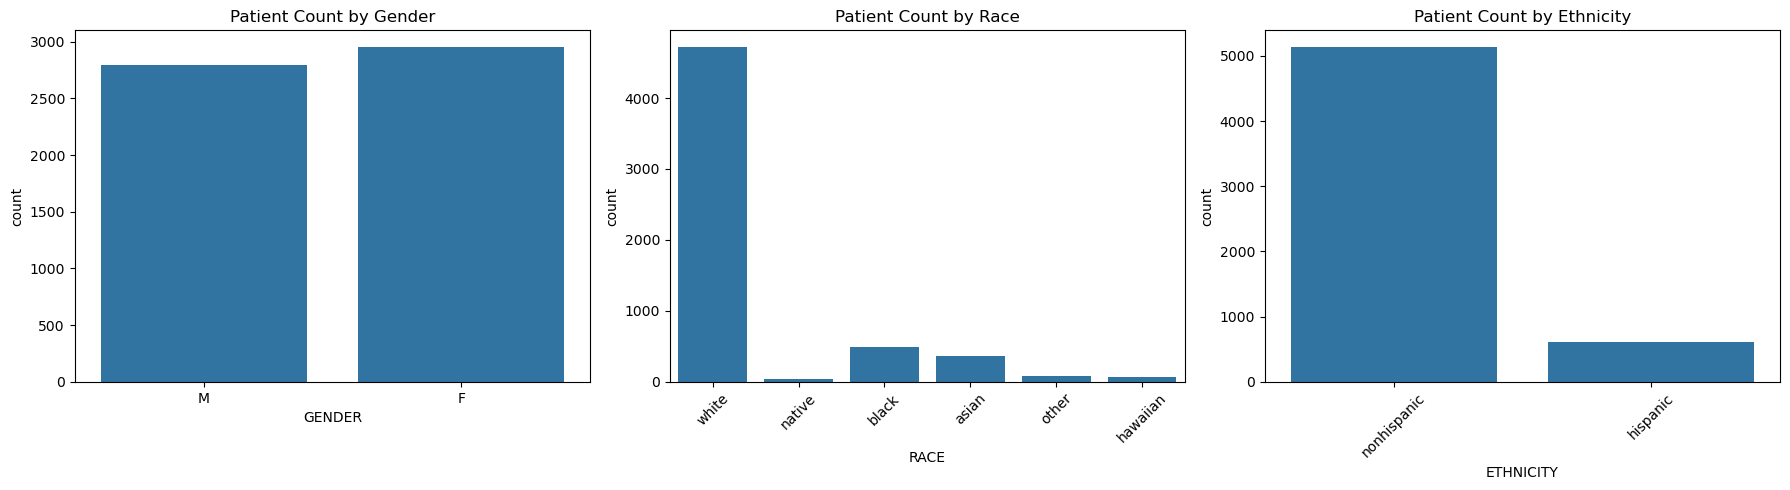

In [22]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
sns.countplot(data=patients_clean, x="GENDER", ax=axes[0])
axes[0].set_title("Patient Count by Gender")

sns.countplot(data=patients_clean, x="RACE", ax=axes[1])
axes[1].set_title("Patient Count by Race")
axes[1].tick_params(axis='x', rotation=45)

sns.countplot(data=patients_clean, x="ETHNICITY", ax=axes[2])
axes[2].set_title("Patient Count by Ethnicity")
axes[2].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()


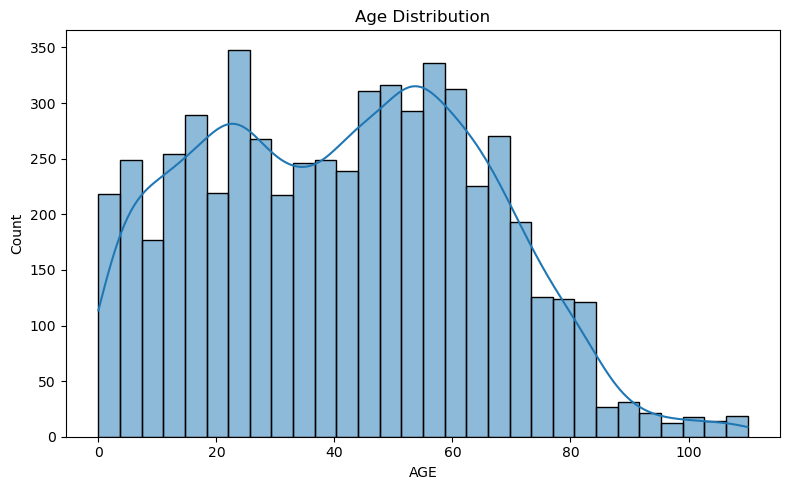

In [23]:
plt.figure(figsize=(8, 5))
sns.histplot(data=patients_clean, x="AGE", bins=30, kde=True)
plt.title("Age Distribution")
plt.tight_layout()
plt.show()

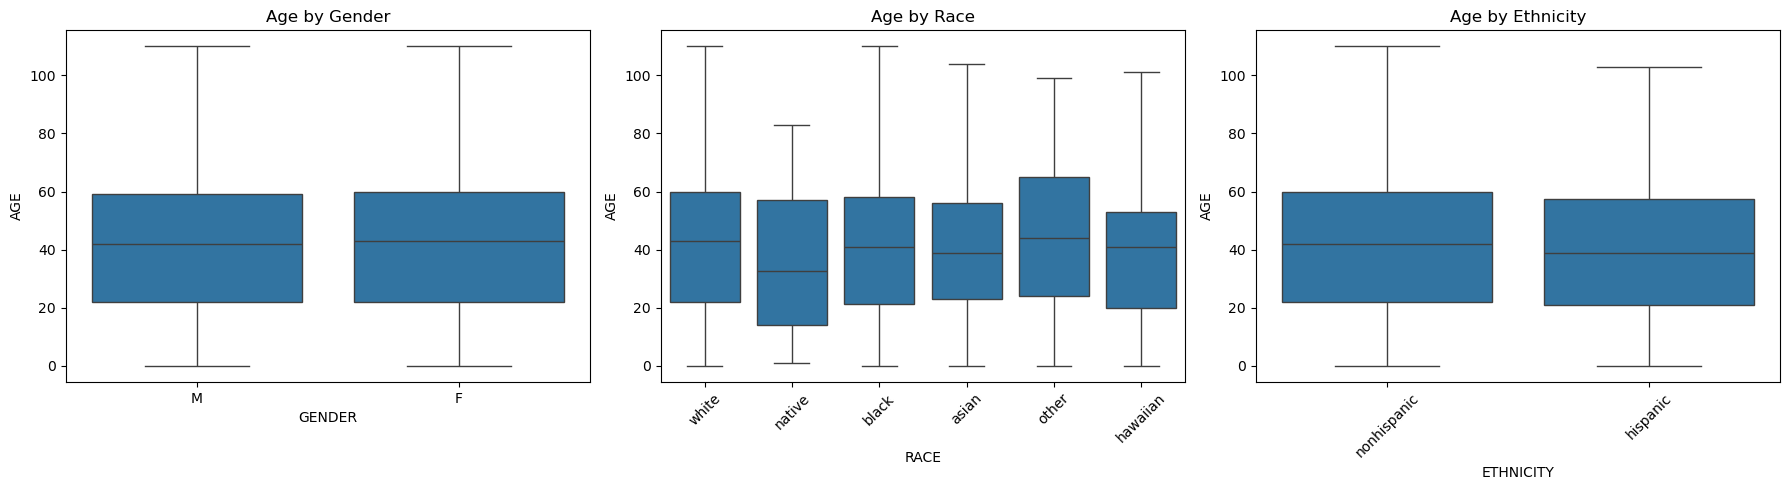

In [24]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
sns.boxplot(data=patients_clean, x="GENDER", y="AGE", ax=axes[0])
axes[0].set_title("Age by Gender")

sns.boxplot(data=patients_clean, x="RACE", y="AGE", ax=axes[1])
axes[1].set_title("Age by Race")
axes[1].tick_params(axis='x', rotation=45)

sns.boxplot(data=patients_clean, x="ETHNICITY", y="AGE", ax=axes[2])
axes[2].set_title("Age by Ethnicity")
axes[2].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

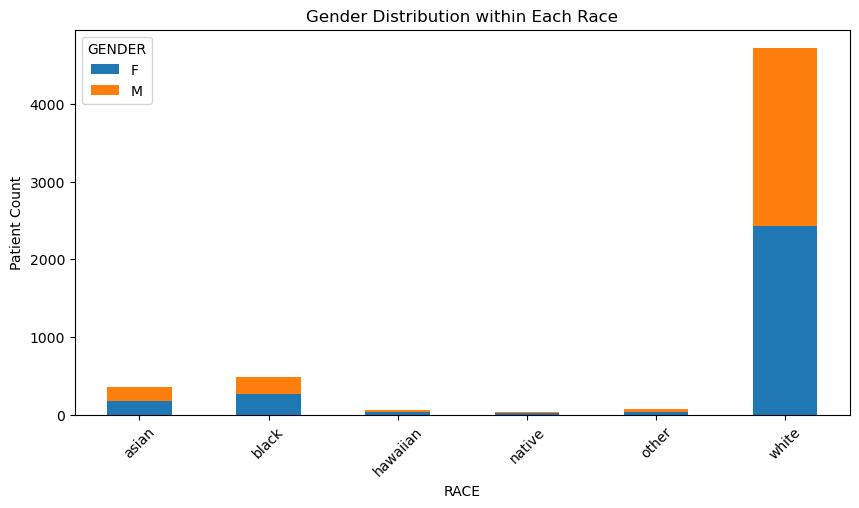

In [25]:
gender_race = patients_clean.groupby(["RACE", "GENDER"]).size().unstack(fill_value=0)
gender_race.plot(kind="bar", stacked=True, figsize=(10, 5))
plt.title("Gender Distribution within Each Race")
plt.ylabel("Patient Count")
plt.xticks(rotation=45)
plt.show()

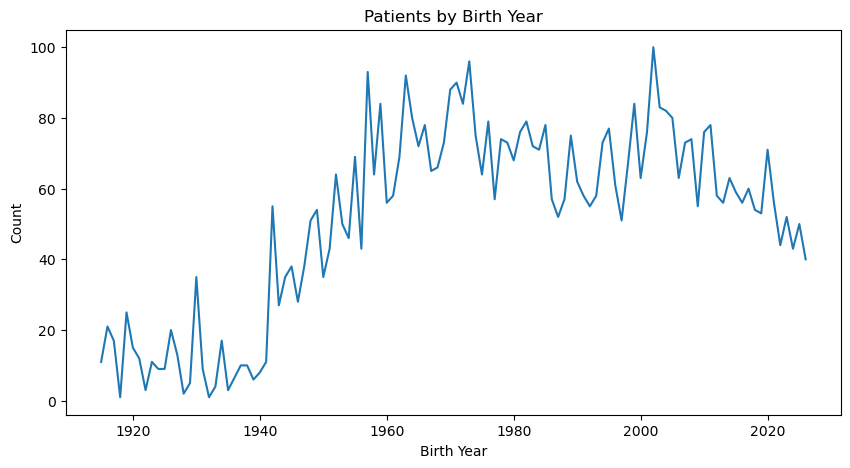

In [26]:
patients_clean["BIRTH_YEAR"] = patients_clean["BIRTHDATE"].dt.year
births_per_year = patients_clean.groupby("BIRTH_YEAR").size()

plt.figure(figsize=(10, 5))
births_per_year.plot(kind="line")
plt.title("Patients by Birth Year")
plt.xlabel("Birth Year")
plt.ylabel("Count")
plt.show()

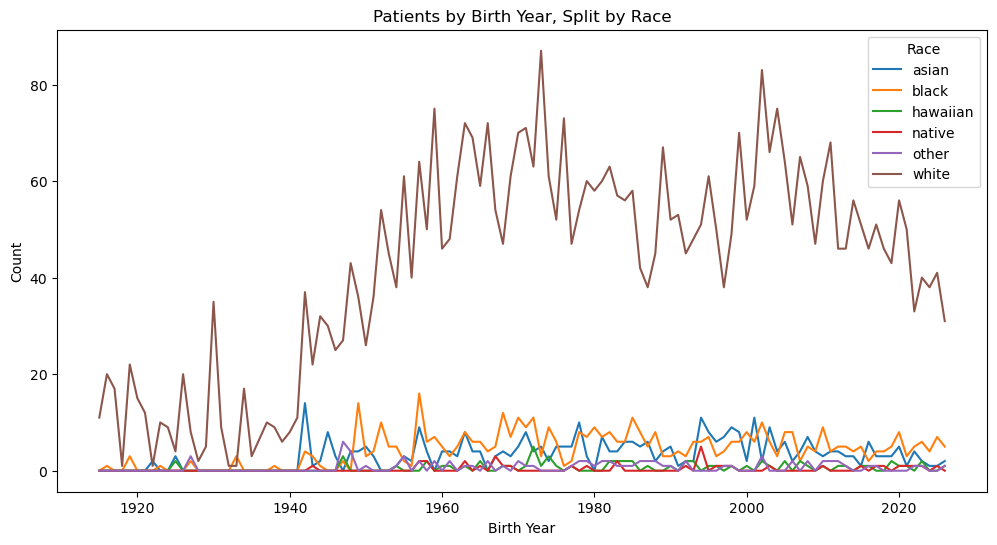

In [27]:
patients_clean["BIRTH_YEAR"] = patients_clean["BIRTHDATE"].dt.year

births_by_race = patients_clean.groupby(["BIRTH_YEAR", "RACE"]).size().unstack(fill_value=0)

plt.figure(figsize=(12, 6))
for race in births_by_race.columns:
    plt.plot(births_by_race.index, births_by_race[race], label=race)

plt.title("Patients by Birth Year, Split by Race")
plt.xlabel("Birth Year")
plt.ylabel("Count")
plt.legend(title="Race")
plt.show()

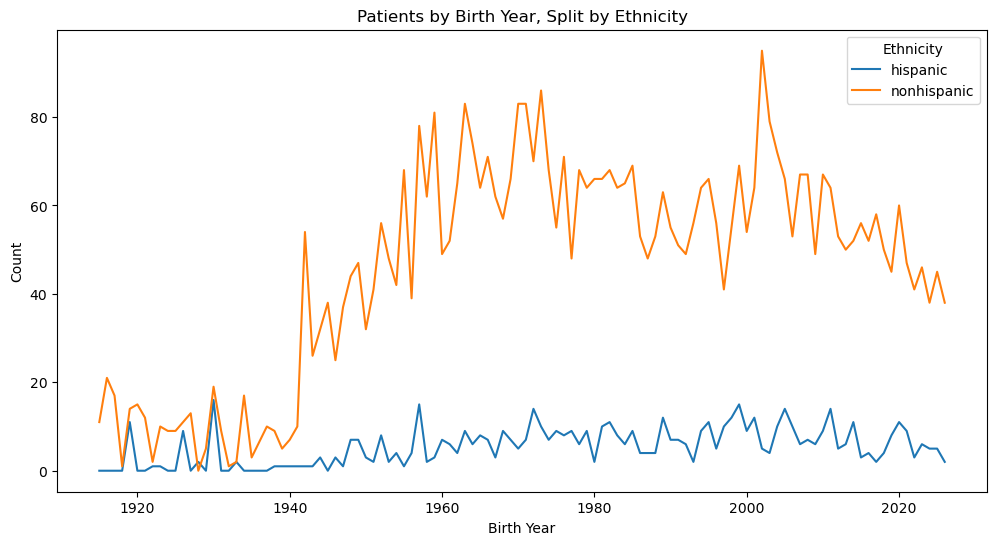

In [28]:
births_by_eth = patients_clean.groupby(["BIRTH_YEAR", "ETHNICITY"]).size().unstack(fill_value=0)

plt.figure(figsize=(12, 6))
for eth in births_by_eth.columns:
    plt.plot(births_by_eth.index, births_by_eth[eth], label=eth)

plt.title("Patients by Birth Year, Split by Ethnicity")
plt.xlabel("Birth Year")
plt.ylabel("Count")
plt.legend(title="Ethnicity")
plt.show()


In [29]:
conditions.head()

,START,STOP,PATIENT,ENCOUNTER,SYSTEM,CODE,DESCRIPTION
0,2018-03-15,2018-03-15,76b20010-c318-5754-8c85-983aa538522f,76b20010-c318-5754-57e2-651f596ddb8c,SNOMED-CT,314529007,Medication review due (situation)
1,2020-02-17,2020-02-17,2d68ad16-268a-478c-1f84-d0f1976e1a46,2d68ad16-268a-478c-73b1-09735410738b,SNOMED-CT,314529007,Medication review due (situation)
2,2018-04-19,2018-06-21,76b20010-c318-5754-8c85-983aa538522f,76b20010-c318-5754-d83c-7cf85a83d079,SNOMED-CT,314529007,Medication review due (situation)
3,2020-03-23,2020-03-23,2d68ad16-268a-478c-1f84-d0f1976e1a46,2d68ad16-268a-478c-a67e-99103873e50d,SNOMED-CT,314529007,Medication review due (situation)
4,2020-05-25,2021-01-25,2d68ad16-268a-478c-1f84-d0f1976e1a46,2d68ad16-268a-478c-26a0-c6716d513154,SNOMED-CT,314529007,Medication review due (situation)


In [30]:
conditions.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 357264 entries, 0 to 357263
Data columns (total 7 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   START        357264 non-null  datetime64[ns]
 1   STOP         304445 non-null  object        
 2   PATIENT      357264 non-null  object        
 3   ENCOUNTER    357264 non-null  object        
 4   SYSTEM       357264 non-null  object        
 5   CODE         357264 non-null  int64         
 6   DESCRIPTION  357264 non-null  object        
dtypes: datetime64[ns](1), int64(1), object(5)
memory usage: 19.1+ MB


In [31]:
conditions["STOP"] = pd.to_datetime(conditions["STOP"])

In [32]:
conditions.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 357264 entries, 0 to 357263
Data columns (total 7 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   START        357264 non-null  datetime64[ns]
 1   STOP         304445 non-null  datetime64[ns]
 2   PATIENT      357264 non-null  object        
 3   ENCOUNTER    357264 non-null  object        
 4   SYSTEM       357264 non-null  object        
 5   CODE         357264 non-null  int64         
 6   DESCRIPTION  357264 non-null  object        
dtypes: datetime64[ns](2), int64(1), object(4)
memory usage: 19.1+ MB


In [33]:
conditions.describe()

,START,STOP,CODE
count,357264,304445,3.572640e+05
mean,2011-01-29 06:01:29.238210304,2012-10-11 13:42:26.576229120,5.289699e+13
min,1917-03-08 00:00:00,1919-08-29 00:00:00,1.734006e+06
25%,2005-04-06 00:00:00,2007-01-27 00:00:00,7.359500e+07
50%,2013-11-02 00:00:00,2014-10-12 00:00:00,2.131500e+08
75%,2020-08-06 00:00:00,2021-01-13 00:00:00,3.145290e+08
max,2026-09-29 00:00:00,2026-09-28 00:00:00,1.093988e+16
std,NaN,NaN,7.552953e+14


In [34]:
conditions.shape

(357264, 7)

In [35]:
conditions.columns

Index(['START', 'STOP', 'PATIENT', 'ENCOUNTER', 'SYSTEM', 'CODE',
       'DESCRIPTION'],
      dtype='object')

In [36]:
conditions['DESCRIPTION'].unique()

array(['Medication review due (situation)', 'Acute bronchitis (disorder)',
       'Acute viral pharyngitis (disorder)',
       'Gingival disease (disorder)', 'Primary dental caries (disorder)',
       'Otitis media (disorder)', 'Infection of tooth (disorder)',
       'Viral sinusitis (disorder)', 'Fracture of bone (disorder)',
       'Fracture of forearm (disorder)',
       'Suspected disease caused by Severe acute respiratory coronavirus 2 (situation)',
       'Cough (finding)', 'Sputum finding (finding)', 'Fatigue (finding)',
       'Fever (finding)', 'Loss of taste (finding)',
       'Disease caused by severe acute respiratory syndrome coronavirus 2 (disorder)',
       'Streptococcal sore throat (disorder)', 'Gingivitis (disorder)',
       'Laceration - injury (disorder)', 'Laceration of thigh (disorder)',
       'Sinusitis (disorder)', 'Risk activity involvement (finding)',
       'Acute bacterial sinusitis (disorder)',
       'Leaking dental filling (finding)',
       'Sprain (mor

In [37]:
conditions.DESCRIPTION.value_counts()

DESCRIPTION
Medication review due (situation)    79125
Gingivitis (disorder)                29933
Stress (finding)                     27553
Full-time employment (finding)       24962
Part-time employment (finding)       16536
                                     ...  
Acute myeloid leukemia (disorder)        1
Bacteremia (finding)                     1
Lupus erythematosus (disorder)           1
Spina bifida occulta (disorder)          1
High risk pregnancy (finding)            1
Name: count, Length: 300, dtype: int64

In [38]:
conditions['DESCRIPTION'].nunique()

300

In [39]:
conditions.isnull().sum()

START              0
STOP           52819
PATIENT            0
ENCOUNTER          0
SYSTEM             0
CODE               0
DESCRIPTION        0
dtype: int64

In [40]:
conditions.duplicated().sum()

np.int64(0)

In [41]:
conditions_clean = conditions[["PATIENT", "DESCRIPTION", "START", "STOP"]].copy()

In [42]:
conditions_clean.head()

,PATIENT,DESCRIPTION,START,STOP
0,76b20010-c318-5754-8c85-983aa538522f,Medication review due (situation),2018-03-15,2018-03-15
1,2d68ad16-268a-478c-1f84-d0f1976e1a46,Medication review due (situation),2020-02-17,2020-02-17
2,76b20010-c318-5754-8c85-983aa538522f,Medication review due (situation),2018-04-19,2018-06-21
3,2d68ad16-268a-478c-1f84-d0f1976e1a46,Medication review due (situation),2020-03-23,2020-03-23
4,2d68ad16-268a-478c-1f84-d0f1976e1a46,Medication review due (situation),2020-05-25,2021-01-25


In [43]:
encounters.head()

,Id,START,STOP,PATIENT,ORGANIZATION,PROVIDER,PAYER,ENCOUNTERCLASS,CODE,DESCRIPTION,BASE_ENCOUNTER_COST,TOTAL_CLAIM_COST,PAYER_COVERAGE,REASONCODE,REASONDESCRIPTION
0,76b20010-c318-5754-57e2-651f596ddb8c,2018-03-15 01:41:45+00:00,2018-03-15T01:56:45Z,76b20010-c318-5754-8c85-983aa538522f,8ce066ae-10ad-3679-9272-387e8cb21947,34059ae7-a6ce-3851-be6f-61ff887f3344,d31fccc3-1767-390d-966a-22a5156f4219,wellness,410620009,Well child visit (procedure),136.8,750.25,0.00,NaN,NaN
1,2d68ad16-268a-478c-73b1-09735410738b,2020-02-17 08:15:15+00:00,2020-02-17T08:30:15Z,2d68ad16-268a-478c-1f84-d0f1976e1a46,e49b692f-cccc-3cd5-93df-6db63dfc3e4a,861c5698-dc95-389f-928c-4d2fe5ef0692,26aab0cd-6aba-3e1b-ac5b-05c8867e762c,wellness,410620009,Well child visit (procedure),136.8,563.08,0.00,NaN,NaN
2,76b20010-c318-5754-d83c-7cf85a83d079,2018-04-19 01:41:45+00:00,2018-04-19T01:56:45Z,76b20010-c318-5754-8c85-983aa538522f,8ce066ae-10ad-3679-9272-387e8cb21947,34059ae7-a6ce-3851-be6f-61ff887f3344,d31fccc3-1767-390d-966a-22a5156f4219,wellness,410620009,Well child visit (procedure),136.8,272.80,0.00,NaN,NaN
3,2d68ad16-268a-478c-a67e-99103873e50d,2020-03-23 08:15:15+00:00,2020-03-23T08:30:15Z,2d68ad16-268a-478c-1f84-d0f1976e1a46,e49b692f-cccc-3cd5-93df-6db63dfc3e4a,861c5698-dc95-389f-928c-4d2fe5ef0692,26aab0cd-6aba-3e1b-ac5b-05c8867e762c,wellness,410620009,Well child visit (procedure),136.8,857.32,0.00,NaN,NaN
4,76b20010-c318-5754-f57b-839fffa306df,2018-06-21 01:41:45+00:00,2018-06-21T01:56:45Z,76b20010-c318-5754-8c85-983aa538522f,8ce066ae-10ad-3679-9272-387e8cb21947,34059ae7-a6ce-3851-be6f-61ff887f3344,d31fccc3-1767-390d-966a-22a5156f4219,wellness,410620009,Well child visit (procedure),136.8,1032.50,478.04,NaN,NaN


In [44]:
encounters.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 582769 entries, 0 to 582768
Data columns (total 15 columns):
 #   Column               Non-Null Count   Dtype              
---  ------               --------------   -----              
 0   Id                   582769 non-null  object             
 1   START                582769 non-null  datetime64[ns, UTC]
 2   STOP                 582769 non-null  object             
 3   PATIENT              582769 non-null  object             
 4   ORGANIZATION         582769 non-null  object             
 5   PROVIDER             582769 non-null  object             
 6   PAYER                582769 non-null  object             
 7   ENCOUNTERCLASS       582769 non-null  object             
 8   CODE                 582769 non-null  int64              
 9   DESCRIPTION          582769 non-null  object             
 10  BASE_ENCOUNTER_COST  582769 non-null  float64            
 11  TOTAL_CLAIM_COST     582769 non-null  float64            
 12  PA

In [45]:
encounters["STOP"] = pd.to_datetime(encounters["STOP"])

In [46]:
encounters.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 582769 entries, 0 to 582768
Data columns (total 15 columns):
 #   Column               Non-Null Count   Dtype              
---  ------               --------------   -----              
 0   Id                   582769 non-null  object             
 1   START                582769 non-null  datetime64[ns, UTC]
 2   STOP                 582769 non-null  datetime64[ns, UTC]
 3   PATIENT              582769 non-null  object             
 4   ORGANIZATION         582769 non-null  object             
 5   PROVIDER             582769 non-null  object             
 6   PAYER                582769 non-null  object             
 7   ENCOUNTERCLASS       582769 non-null  object             
 8   CODE                 582769 non-null  int64              
 9   DESCRIPTION          582769 non-null  object             
 10  BASE_ENCOUNTER_COST  582769 non-null  float64            
 11  TOTAL_CLAIM_COST     582769 non-null  float64            
 12  PA

In [47]:
encounters.describe()

,CODE,BASE_ENCOUNTER_COST,TOTAL_CLAIM_COST,PAYER_COVERAGE,REASONCODE
count,5.827690e+05,582769.000000,582769.000000,582769.000000,3.768510e+05
mean,5.780462e+10,114.762551,2937.563591,2012.795547,6.587406e+11
std,5.105802e+12,27.435498,6605.279298,5450.179029,1.130665e+13
min,1.505002e+06,75.000000,75.000000,0.000000,1.734006e+06
25%,1.853450e+08,85.550000,516.950000,0.000000,6.638301e+07
50%,1.853490e+08,136.800000,944.880000,447.940000,1.036970e+08
75%,3.909060e+08,142.580000,3105.350000,1390.380000,4.318570e+08
max,4.531310e+14,146.180000,471912.800000,283420.610000,4.425710e+14


In [48]:
encounters.shape

(582769, 15)

In [49]:
encounters.columns

Index(['Id', 'START', 'STOP', 'PATIENT', 'ORGANIZATION', 'PROVIDER', 'PAYER',
       'ENCOUNTERCLASS', 'CODE', 'DESCRIPTION', 'BASE_ENCOUNTER_COST',
       'TOTAL_CLAIM_COST', 'PAYER_COVERAGE', 'REASONCODE',
       'REASONDESCRIPTION'],
      dtype='object')

In [50]:
encounters['ENCOUNTERCLASS'].unique()

array(['wellness', 'ambulatory', 'outpatient', 'emergency', 'snf',
       'urgentcare', 'virtual', 'hospice', 'inpatient', 'home'],
      dtype=object)

In [51]:
encounters['REASONDESCRIPTION'].unique()

array([nan, 'Acute bronchitis (disorder)',
       'Acute viral pharyngitis (disorder)',
       'Patient referral for dental care (procedure)',
       'Otitis media (disorder)', 'Viral sinusitis (disorder)',
       'Fracture of bone (disorder)', 'Fracture of forearm (disorder)',
       'Suspected disease caused by Severe acute respiratory coronavirus 2 (situation)',
       'Streptococcal sore throat (disorder)', 'Gingivitis (disorder)',
       'Laceration - injury (disorder)',
       'Acute bacterial sinusitis (disorder)', 'Sinusitis (disorder)',
       'Sprain (morphologic abnormality)',
       'Contraception care (regime/therapy)',
       'Burn injury (morphologic abnormality)',
       'Patient transfer to skilled nursing facility (procedure)',
       'Epidermal burn of skin (disorder)',
       'Acute infective cystitis (disorder)',
       'Concussion injury of brain (disorder)',
       'Concussion with no loss of consciousness (disorder)',
       'Peanut (substance)', 'Allergic dispo

In [52]:
encounters_clean = encounters[["PATIENT", "REASONDESCRIPTION", "ENCOUNTERCLASS", "START", "STOP"]].copy()

In [53]:
encounters_clean.head()

,PATIENT,REASONDESCRIPTION,ENCOUNTERCLASS,START,STOP
0,76b20010-c318-5754-8c85-983aa538522f,NaN,wellness,2018-03-15 01:41:45+00:00,2018-03-15 01:56:45+00:00
1,2d68ad16-268a-478c-1f84-d0f1976e1a46,NaN,wellness,2020-02-17 08:15:15+00:00,2020-02-17 08:30:15+00:00
2,76b20010-c318-5754-8c85-983aa538522f,NaN,wellness,2018-04-19 01:41:45+00:00,2018-04-19 01:56:45+00:00
3,2d68ad16-268a-478c-1f84-d0f1976e1a46,NaN,wellness,2020-03-23 08:15:15+00:00,2020-03-23 08:30:15+00:00
4,76b20010-c318-5754-8c85-983aa538522f,NaN,wellness,2018-06-21 01:41:45+00:00,2018-06-21 01:56:45+00:00


In [54]:
encounters_clean.ENCOUNTERCLASS.value_counts()

ENCOUNTERCLASS
ambulatory    321051
wellness      124367
outpatient     76393
emergency      24658
urgentcare     23224
inpatient       6333
home            2999
snf             1683
virtual         1134
hospice          927
Name: count, dtype: int64

In [55]:
encounters_clean.REASONDESCRIPTION.value_counts()

REASONDESCRIPTION
Chronic kidney disease stage 4 (disorder)       52961
Normal pregnancy (finding)                      43500
Contraception care (regime/therapy)             34118
Patient referral for dental care (procedure)    32522
Gingivitis (disorder)                           29376
                                                ...  
Cardiac arrest (disorder)                           2
Suicidal poisoning (disorder)                       1
Tricuspid valve stenosis (disorder)                 1
Acute myeloid leukemia (disorder)                   1
Spina bifida occulta (disorder)                     1
Name: count, Length: 168, dtype: int64

In [56]:
medications.head()

,START,STOP,PATIENT,PAYER,ENCOUNTER,CODE,DESCRIPTION,BASE_COST,PAYER_COVERAGE,DISPENSES,TOTALCOST,REASONCODE,REASONDESCRIPTION
0,2018-06-28 02:01:53+00:00,2018-07-14T02:01:53Z,76b20010-c318-5754-8c85-983aa538522f,d31fccc3-1767-390d-966a-22a5156f4219,76b20010-c318-5754-8283-493693157ccd,313782,Acetaminophen 325 MG Oral Tablet,45.86,36.69,1,45.86,10509002.0,Acute bronchitis (disorder)
1,2022-07-22 01:41:45+00:00,2022-08-05T01:41:45Z,76b20010-c318-5754-8c85-983aa538522f,d31fccc3-1767-390d-966a-22a5156f4219,76b20010-c318-5754-622a-e41e1985aeef,308192,Amoxicillin 500 MG Oral Tablet,142.56,0.00,1,142.56,NaN,NaN
2,2022-07-22 01:41:45+00:00,2022-08-05T01:41:45Z,76b20010-c318-5754-8c85-983aa538522f,d31fccc3-1767-390d-966a-22a5156f4219,76b20010-c318-5754-622a-e41e1985aeef,198405,Ibuprofen 100 MG Oral Tablet,108.56,0.00,1,108.56,NaN,NaN
3,2025-01-13 01:41:45+00:00,2025-01-27T01:41:45Z,76b20010-c318-5754-8c85-983aa538522f,d31fccc3-1767-390d-966a-22a5156f4219,76b20010-c318-5754-0497-211daff5cf73,308192,Amoxicillin 500 MG Oral Tablet,8.67,0.00,1,8.67,NaN,NaN
4,2025-01-13 01:41:45+00:00,2025-01-27T01:41:45Z,76b20010-c318-5754-8c85-983aa538522f,d31fccc3-1767-390d-966a-22a5156f4219,76b20010-c318-5754-0497-211daff5cf73,313820,Acetaminophen 160 MG Chewable Tablet,73.79,0.00,1,73.79,NaN,NaN


In [57]:
medications.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 412661 entries, 0 to 412660
Data columns (total 13 columns):
 #   Column             Non-Null Count   Dtype              
---  ------             --------------   -----              
 0   START              412661 non-null  datetime64[ns, UTC]
 1   STOP               398077 non-null  object             
 2   PATIENT            412661 non-null  object             
 3   PAYER              412661 non-null  object             
 4   ENCOUNTER          412661 non-null  object             
 5   CODE               412661 non-null  int64              
 6   DESCRIPTION        412661 non-null  object             
 7   BASE_COST          412661 non-null  float64            
 8   PAYER_COVERAGE     412661 non-null  float64            
 9   DISPENSES          412661 non-null  int64              
 10  TOTALCOST          412661 non-null  float64            
 11  REASONCODE         333384 non-null  float64            
 12  REASONDESCRIPTION  333384 non-

In [58]:
medications["STOP"] = pd.to_datetime(medications["STOP"])

In [59]:
medications.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 412661 entries, 0 to 412660
Data columns (total 13 columns):
 #   Column             Non-Null Count   Dtype              
---  ------             --------------   -----              
 0   START              412661 non-null  datetime64[ns, UTC]
 1   STOP               398077 non-null  datetime64[ns, UTC]
 2   PATIENT            412661 non-null  object             
 3   PAYER              412661 non-null  object             
 4   ENCOUNTER          412661 non-null  object             
 5   CODE               412661 non-null  int64              
 6   DESCRIPTION        412661 non-null  object             
 7   BASE_COST          412661 non-null  float64            
 8   PAYER_COVERAGE     412661 non-null  float64            
 9   DISPENSES          412661 non-null  int64              
 10  TOTALCOST          412661 non-null  float64            
 11  REASONCODE         333384 non-null  float64            
 12  REASONDESCRIPTION  333384 non-

In [60]:
medications.describe()

,CODE,BASE_COST,PAYER_COVERAGE,DISPENSES,TOTALCOST,REASONCODE
count,4.126610e+05,412661.000000,412661.000000,412661.000000,4.126610e+05,3.333840e+05
mean,5.893632e+05,108.992844,59.805909,5.957752,1.948816e+03,5.568646e+11
std,5.125695e+05,1123.508105,856.899754,36.510191,1.525607e+05,6.492081e+12
min,1.050780e+05,0.000000,0.000000,1.000000,0.000000e+00,5.602001e+06
25%,2.069050e+05,0.910000,0.000000,1.000000,2.730000e+00,5.962100e+07
50%,3.140760e+05,30.670000,0.730000,1.000000,3.067000e+01,6.638301e+07
75%,8.609750e+05,129.940000,79.940000,3.000000,1.299400e+02,2.717370e+08
max,2.563431e+06,103958.400000,103923.400000,1604.000000,3.399440e+07,1.322810e+14


In [61]:
medications.shape

(412661, 13)

In [62]:
medications.columns

Index(['START', 'STOP', 'PATIENT', 'PAYER', 'ENCOUNTER', 'CODE', 'DESCRIPTION',
       'BASE_COST', 'PAYER_COVERAGE', 'DISPENSES', 'TOTALCOST', 'REASONCODE',
       'REASONDESCRIPTION'],
      dtype='object')

In [63]:
medications['DESCRIPTION'].unique()

array(['Acetaminophen 325 MG Oral Tablet',
       'Amoxicillin 500 MG Oral Tablet', 'Ibuprofen 100 MG Oral Tablet',
       'Acetaminophen 160 MG Chewable Tablet',
       'sodium fluoride 0.0272 MG/MG Oral Gel',
       'Amoxicillin 250 MG / Clavulanate 125 MG Oral Tablet',
       'Penicillin V Potassium 250 MG Oral Tablet',
       '{7 (ethinyl estradiol 0.01 MG Oral Tablet) / 84 (ethinyl estradiol 0.03 MG / levonorgestrel 0.15 MG Oral Tablet) } Pack [Seasonique]',
       'Naproxen sodium 220 MG Oral Tablet',
       'ciprofloxacin 250 MG Oral Tablet',
       '{21 (ethinyl estradiol 0.03 MG / levonorgestrel 0.15 MG Oral Tablet) / 7 (inert ingredients 1 MG Oral Tablet) } Pack [Levora 0.15/30 28 Day]',
       '{24 (drospirenone 3 MG / ethinyl estradiol 0.02 MG Oral Tablet) / 4 (inert ingredients 1 MG Oral Tablet) } Pack [Yaz 28 Day]',
       'Amoxicillin 250 MG Oral Capsule',
       'Acetaminophen 21.7 MG/ML / Dextromethorphan Hydrobromide 1 MG/ML / doxylamine succinate 0.417 MG/ML Oral Sol

In [64]:
medications['DESCRIPTION'].nunique()

355

In [65]:
medications_clean = medications[["PATIENT", "DESCRIPTION", "START", "STOP"]].copy()

In [66]:
medications_clean.head()

,PATIENT,DESCRIPTION,START,STOP
0,76b20010-c318-5754-8c85-983aa538522f,Acetaminophen 325 MG Oral Tablet,2018-06-28 02:01:53+00:00,2018-07-14 02:01:53+00:00
1,76b20010-c318-5754-8c85-983aa538522f,Amoxicillin 500 MG Oral Tablet,2022-07-22 01:41:45+00:00,2022-08-05 01:41:45+00:00
2,76b20010-c318-5754-8c85-983aa538522f,Ibuprofen 100 MG Oral Tablet,2022-07-22 01:41:45+00:00,2022-08-05 01:41:45+00:00
3,76b20010-c318-5754-8c85-983aa538522f,Amoxicillin 500 MG Oral Tablet,2025-01-13 01:41:45+00:00,2025-01-27 01:41:45+00:00
4,76b20010-c318-5754-8c85-983aa538522f,Acetaminophen 160 MG Chewable Tablet,2025-01-13 01:41:45+00:00,2025-01-27 01:41:45+00:00


In [67]:
observations.head()

,DATE,PATIENT,ENCOUNTER,CATEGORY,CODE,DESCRIPTION,VALUE,UNITS,TYPE
0,2020-02-17 08:15:15+00:00,2d68ad16-268a-478c-1f84-d0f1976e1a46,2d68ad16-268a-478c-73b1-09735410738b,vital-signs,8302-2,Body Height,50.7,cm,numeric
1,2018-03-15 01:41:45+00:00,76b20010-c318-5754-8c85-983aa538522f,76b20010-c318-5754-57e2-651f596ddb8c,vital-signs,8302-2,Body Height,53.1,cm,numeric
2,2020-02-17 08:15:15+00:00,2d68ad16-268a-478c-1f84-d0f1976e1a46,2d68ad16-268a-478c-73b1-09735410738b,vital-signs,72514-3,Pain severity - 0-10 verbal numeric rating [Sc...,0.0,{score},numeric
3,2018-03-15 01:41:45+00:00,76b20010-c318-5754-8c85-983aa538522f,76b20010-c318-5754-57e2-651f596ddb8c,vital-signs,72514-3,Pain severity - 0-10 verbal numeric rating [Sc...,3.0,{score},numeric
4,2018-03-15 01:41:45+00:00,76b20010-c318-5754-8c85-983aa538522f,76b20010-c318-5754-57e2-651f596ddb8c,vital-signs,29463-7,Body Weight,3.9,kg,numeric


In [68]:
observations.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7605848 entries, 0 to 7605847
Data columns (total 9 columns):
 #   Column       Dtype              
---  ------       -----              
 0   DATE         datetime64[ns, UTC]
 1   PATIENT      object             
 2   ENCOUNTER    object             
 3   CATEGORY     object             
 4   CODE         object             
 5   DESCRIPTION  object             
 6   VALUE        object             
 7   UNITS        object             
 8   TYPE         object             
dtypes: datetime64[ns, UTC](1), object(8)
memory usage: 522.3+ MB


In [69]:
observations.describe()

,DATE,PATIENT,ENCOUNTER,CATEGORY,CODE,DESCRIPTION,VALUE,UNITS,TYPE
count,7605848,7605848,7250612,7250612,7605848,7605848,7605848,5419735,7605848
unique,NaN,5743,308382,8,294,296,16025,51,2
top,NaN,c507ce58-4d43-22e3-43f6-f863c2b1ad4a,a0b986aa-6af3-519e-a10c-10fc42d0ef21,laboratory,72514-3,Pain severity - 0-10 verbal numeric rating [Sc...,No,mg/dL,numeric
freq,NaN,36262,1406,3028758,232735,232735,747156,988355,4675415
mean,2012-09-15 16:19:58.289242368+00:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
min,1919-07-25 14:22:43+00:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
25%,2006-11-25 03:19:29+00:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
50%,2014-12-19 20:40:01+00:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
75%,2021-03-07 07:10:52.249999872+00:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
max,2026-09-28 20:16:25+00:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [70]:
observations.shape

(7605848, 9)

In [71]:
observations.columns

Index(['DATE', 'PATIENT', 'ENCOUNTER', 'CATEGORY', 'CODE', 'DESCRIPTION',
       'VALUE', 'UNITS', 'TYPE'],
      dtype='object')

In [72]:
observations.DESCRIPTION.value_counts()

DESCRIPTION
Pain severity - 0-10 verbal numeric rating [Score] - Reported    232735
Systolic Blood Pressure                                          163332
Diastolic Blood Pressure                                         163332
Body Weight                                                      157419
Heart rate                                                       155426
                                                                  ...  
PROMIS-29 Pain interference score                                     4
PROMIS-29 Sleep disturbance score                                     4
Bacteria identified in Blood by Culture                               2
Toxoplasma gondii Ab [Presence] in Serum                              1
Body Temperature                                                      1
Name: count, Length: 296, dtype: int64

In [73]:
observations.CATEGORY.value_counts()

CATEGORY
laboratory        3028758
survey            2501006
vital-signs       1524225
social-history     159730
exam                25323
procedure            6124
imaging              4507
therapy               939
Name: count, dtype: int64

In [74]:
observations['CATEGORY'].unique()

array(['vital-signs', 'laboratory', 'social-history', nan, 'survey',
       'exam', 'procedure', 'imaging', 'therapy'], dtype=object)

In [75]:
observations['CATEGORY'].nunique()

8

In [76]:
observations_clean = observations[["PATIENT", "CATEGORY", "DATE", "DESCRIPTION", "VALUE", "TYPE", "UNITS"]].copy()

In [77]:
observations_clean.head()

,PATIENT,CATEGORY,DATE,DESCRIPTION,VALUE,TYPE,UNITS
0,2d68ad16-268a-478c-1f84-d0f1976e1a46,vital-signs,2020-02-17 08:15:15+00:00,Body Height,50.7,numeric,cm
1,76b20010-c318-5754-8c85-983aa538522f,vital-signs,2018-03-15 01:41:45+00:00,Body Height,53.1,numeric,cm
2,2d68ad16-268a-478c-1f84-d0f1976e1a46,vital-signs,2020-02-17 08:15:15+00:00,Pain severity - 0-10 verbal numeric rating [Sc...,0.0,numeric,{score}
3,76b20010-c318-5754-8c85-983aa538522f,vital-signs,2018-03-15 01:41:45+00:00,Pain severity - 0-10 verbal numeric rating [Sc...,3.0,numeric,{score}
4,76b20010-c318-5754-8c85-983aa538522f,vital-signs,2018-03-15 01:41:45+00:00,Body Weight,3.9,numeric,kg


In [78]:
observations['DESCRIPTION'].unique()

array(['Body Height',
       'Pain severity - 0-10 verbal numeric rating [Score] - Reported',
       'Body Weight', 'Weight-for-length Per age and sex',
       'Head Occipital-frontal circumference Percentile',
       'Head Occipital-frontal circumference', 'Diastolic Blood Pressure',
       'Systolic Blood Pressure', 'Heart rate', 'Respiratory rate',
       'Leukocytes [#/volume] in Blood by Automated count',
       'Erythrocytes [#/volume] in Blood by Automated count',
       'Hemoglobin [Mass/volume] in Blood',
       'Hematocrit [Volume Fraction] of Blood by Automated count',
       'MCV [Entitic mean volume] in Red Blood Cells by Automated count',
       'MCH [Entitic mass] by Automated count',
       'MCHC [Entitic Mass/volume] in Red Blood Cells by Automated count',
       'Erythrocyte [DistWidth] in Blood by Automated count',
       'Platelets [#/volume] in Blood by Automated count',
       'Platelet distribution width [Entitic volume] in Blood by Automated count',
       'Plat

In [79]:
observations['DESCRIPTION'].nunique()

296

In [80]:
pd.set_option("display.max_rows", None)
conditions_clean.DESCRIPTION.value_counts()

DESCRIPTION
Medication review due (situation)                                                 79125
Gingivitis (disorder)                                                             29933
Stress (finding)                                                                  27553
Full-time employment (finding)                                                    24962
Part-time employment (finding)                                                    16536
Viral sinusitis (disorder)                                                        13364
Social isolation (finding)                                                         9607
Limited social contact (finding)                                                   9543
Not in labor force (finding)                                                       9086
Gingival disease (disorder)                                                        8969
Acute viral pharyngitis (disorder)                                                 7774
Primary dental carie

In [81]:
pd.reset_option("display.max_rows")

In [82]:
pd.set_option("display.max_rows", None)
observations_clean.DESCRIPTION.value_counts()

DESCRIPTION
Pain severity - 0-10 verbal numeric rating [Score] - Reported                                                                                                                                                                 232735
Systolic Blood Pressure                                                                                                                                                                                                       163332
Diastolic Blood Pressure                                                                                                                                                                                                      163332
Body Weight                                                                                                                                                                                                                   157419
Heart rate                                                              

In [83]:
targets_final = {
    "Diabetes": ["Diabetes mellitus type 2 (disorder)"],
    "Hypertension": ["Essential hypertension (disorder)"],
    "CKD": ["Chronic kidney disease stage 1 (disorder)", "Chronic kidney disease stage 2 (disorder)",
            "Chronic kidney disease stage 3 (disorder)", "Chronic kidney disease stage 4 (disorder)"],
    "Hyperlipidemia": ["Hyperlipidemia (disorder)"],
    "Anemia": ["Anemia (disorder)"]
}

In [84]:
selected_labs = [
    "Systolic Blood Pressure", "Diastolic Blood Pressure", "Body Weight", "Body Height",
    "Body mass index (BMI) [Ratio]", "Heart rate", "Respiratory rate",
    "Glomerular filtration rate [Volume Rate/Area] in Serum or Plasma by Creatinine-based formula (MDRD)/1.73 sq M",
    "Creatinine [Mass/volume] in Blood", "Urea nitrogen [Mass/volume] in Blood",
    "Microalbumin/Creatinine [Mass Ratio] in Urine",
    "Hemoglobin A1c/Hemoglobin.total in Blood", "Glucose [Mass/volume] in Blood",
    "Cholesterol [Mass/volume] in Serum or Plasma",
    "Cholesterol in LDL [Mass/volume] in Serum or Plasma by Direct assay",
    "Cholesterol in HDL [Mass/volume] in Serum or Plasma",
    "Triglyceride [Mass/volume] in Serum or Plasma",
    "Hemoglobin [Mass/volume] in Blood"
]

In [85]:
for df, col in [(conditions_clean, "START"),
                 (encounters_clean, "START"), (encounters_clean, "STOP"),
                 (medications_clean, "START"), (medications_clean, "STOP"),
                 (observations_clean, "DATE")]:
    if df[col].dt.tz is None:
        df[col] = df[col].dt.tz_localize("UTC")
    else:
        df[col] = df[col].dt.tz_convert("UTC")

In [86]:
print("conditions:  ", conditions_clean["START"].min(), "to", conditions_clean["START"].max())
print("encounters:  ", encounters_clean["START"].min(), "to", encounters_clean["START"].max())
print("observations:", observations_clean["DATE"].min(), "to", observations_clean["DATE"].max())
print("medications: ", medications_clean["START"].min(), "to", medications_clean["START"].max())

conditions:   1917-03-08 00:00:00+00:00 to 2026-09-29 00:00:00+00:00
encounters:   1917-03-08 05:15:09+00:00 to 2026-09-28 20:16:25+00:00
observations: 1919-07-25 14:22:43+00:00 to 2026-09-28 20:16:25+00:00
medications:  1920-01-21 14:22:43+00:00 to 2026-09-28 19:38:24+00:00


In [87]:
ckd_stage_names = ["Chronic kidney disease stage 1 (disorder)", "Chronic kidney disease stage 2 (disorder)",
                    "Chronic kidney disease stage 3 (disorder)", "Chronic kidney disease stage 4 (disorder)"]

ckd_all = conditions_clean[conditions_clean.DESCRIPTION.isin(ckd_stage_names)].copy()

#ckd diagnosis by start and end date and their stages
progression = ckd_all.groupby("PATIENT")["START"].agg(["min", "max"])
progression["years_first_to_last"] = (progression["max"] - progression["min"]).dt.days / 365.25

progressed = progression[progression["max"] > progression["min"]]
print("Patients with multi-stage progression:", len(progressed))
print(progressed["years_first_to_last"].describe())

Patients with multi-stage progression: 438
count    438.000000
mean      11.157286
std        9.298421
min        0.172485
25%        3.847365
50%        8.911704
75%       16.266256
max       46.494182
Name: years_first_to_last, dtype: float64


In [88]:
stage_map = {name: i+1 for i, name in enumerate(ckd_stage_names)}
ckd_all["STAGE_NUM"] = ckd_all["DESCRIPTION"].map(stage_map)
first_per_stage = ckd_all.groupby(["PATIENT", "STAGE_NUM"])["START"].min().unstack()

for a, b in [(1,2), (2,3), (3,4)]:
    if a in first_per_stage.columns and b in first_per_stage.columns:
        pair = first_per_stage[[a, b]].dropna()
        gap_years = (pair[b] - pair[a]).dt.days / 365.25
        print(f"Stage {a} -> {b}: n={len(gap_years)}, median={gap_years.median():.2f} years")

Stage 1 -> 2: n=407, median=2.22 years
Stage 2 -> 3: n=309, median=4.20 years
Stage 3 -> 4: n=196, median=4.05 years


In [89]:
prediab_dates = conditions_clean[conditions_clean.DESCRIPTION == "Prediabetes (finding)"].groupby("PATIENT")["START"].min()
diab_dates = conditions_clean[conditions_clean.DESCRIPTION == "Diabetes mellitus type 2 (disorder)"].groupby("PATIENT")["START"].min()

both_d = pd.concat([prediab_dates.rename("prediab"), diab_dates.rename("diabetes")], axis=1).dropna()
both_d["years_prediab_to_diabetes"] = (both_d["diabetes"] - both_d["prediab"]).dt.days / 365.25
print(both_d["years_prediab_to_diabetes"].describe())

count    295.000000
mean      20.631497
std       11.184914
min        1.015743
25%       11.843943
50%       20.851472
75%       28.325804
max       53.834360
Name: years_prediab_to_diabetes, dtype: float64


In [90]:
conditions_clean = conditions_clean.rename(columns={"DESCRIPTION": "CONDITION_DESC"})
medications_clean = medications_clean.rename(columns={"DESCRIPTION": "MEDICATION_DESC"})
observations_clean = observations_clean.rename(columns={"DESCRIPTION": "OBSERVATION_DESC"})

In [91]:
labels = patients_clean[["PATIENT"]].copy()

for disease, names in targets_final.items():
    cases = conditions_clean[conditions_clean.CONDITION_DESC.isin(names)]
    first_diag = cases.groupby("PATIENT")["START"].min().rename(f"{disease}_DIAG_DATE")
    labels = labels.merge(first_diag, on="PATIENT", how="left")

for disease in targets_final:
    print(disease, "non-null dates:", labels[f"{disease}_DIAG_DATE"].notna().sum())

Diabetes non-null dates: 400
Hypertension non-null dates: 1246
CKD non-null dates: 522
Hyperlipidemia non-null dates: 571
Anemia non-null dates: 2256


In [92]:
last_encounter = encounters_clean.groupby("PATIENT")["START"].max().rename("LAST_ENCOUNTER")
labels = labels.merge(last_encounter, on="PATIENT", how="left")

In [93]:
GAP_YEARS = 2

for disease in targets_final:
    diag_col = f"{disease}_DIAG_DATE"
    snap_col = f"{disease}_SNAPSHOT"

    diag_snapshot = labels[diag_col] - pd.DateOffset(years=GAP_YEARS)
    never_diag_snapshot = labels["LAST_ENCOUNTER"] - pd.DateOffset(years=GAP_YEARS)

    labels[snap_col] = np.where(labels[diag_col].notna(), diag_snapshot, never_diag_snapshot)
    labels[snap_col] = pd.to_datetime(labels[snap_col], utc=True)

    labels[f"{disease}_LABEL"] = labels[diag_col].notna().astype(int)


In [94]:
labels.head()

,PATIENT,Diabetes_DIAG_DATE,Hypertension_DIAG_DATE,CKD_DIAG_DATE,Hyperlipidemia_DIAG_DATE,Anemia_DIAG_DATE,LAST_ENCOUNTER,Diabetes_SNAPSHOT,Diabetes_LABEL,Hypertension_SNAPSHOT,Hypertension_LABEL,CKD_SNAPSHOT,CKD_LABEL,Hyperlipidemia_SNAPSHOT,Hyperlipidemia_LABEL,Anemia_SNAPSHOT,Anemia_LABEL
0,76b20010-c318-5754-8c85-983aa538522f,NaT,NaT,NaT,NaT,NaT,2026-03-19 01:41:45+00:00,2024-03-19 01:41:45+00:00,0,2024-03-19 01:41:45+00:00,0,2024-03-19 01:41:45+00:00,0,2024-03-19 01:41:45+00:00,0,2024-03-19 01:41:45+00:00,0
1,2d68ad16-268a-478c-1f84-d0f1976e1a46,NaT,NaT,NaT,NaT,NaT,2026-02-02 08:15:15+00:00,2024-02-02 08:15:15+00:00,0,2024-02-02 08:15:15+00:00,0,2024-02-02 08:15:15+00:00,0,2024-02-02 08:15:15+00:00,0,2024-02-02 08:15:15+00:00,0
2,aee7bbe1-0c45-c028-1e62-1f4cdb30c273,NaT,NaT,NaT,NaT,NaT,2026-02-08 06:07:57+00:00,2024-02-08 06:07:57+00:00,0,2024-02-08 06:07:57+00:00,0,2024-02-08 06:07:57+00:00,0,2024-02-08 06:07:57+00:00,0,2024-02-08 06:07:57+00:00,0
3,46976cf7-b0bf-be20-39a5-9f425a52886d,NaT,NaT,NaT,NaT,NaT,2026-08-15 03:27:26+00:00,2024-08-15 03:27:26+00:00,0,2024-08-15 03:27:26+00:00,0,2024-08-15 03:27:26+00:00,0,2024-08-15 03:27:26+00:00,0,2024-08-15 03:27:26+00:00,0
4,5e688e99-61b3-5c88-3f60-21df8aaced27,NaT,NaT,NaT,NaT,NaT,2026-03-08 03:05:20+00:00,2024-03-08 03:05:20+00:00,0,2024-03-08 03:05:20+00:00,0,2024-03-08 03:05:20+00:00,0,2024-03-08 03:05:20+00:00,0,2024-03-08 03:05:20+00:00,0


In [95]:
patients_clean["BIRTHDATE"] = pd.to_datetime(patients_clean["BIRTHDATE"], utc=True)
patients_clean["DEATHDATE"] = pd.to_datetime(patients_clean["DEATHDATE"], utc=True)

birthdates_df = patients_clean[["PATIENT", "BIRTHDATE"]]
check = labels.merge(birthdates_df, on="PATIENT", how="left")

invalid_patients = set()
for disease in targets_final:
    bad_mask = check[f"{disease}_SNAPSHOT"] < check["BIRTHDATE"]
    print(disease, "invalid:", bad_mask.sum())
    invalid_patients.update(check.loc[bad_mask, "PATIENT"])

labels_clean = labels[~labels["PATIENT"].isin(invalid_patients)].copy()
print("Remaining patients:", len(labels_clean))

for disease in targets_final:
    print(disease, "label=1 count:", labels_clean[f"{disease}_LABEL"].sum())

Diabetes invalid: 122
Hypertension invalid: 122
CKD invalid: 122
Hyperlipidemia invalid: 122
Anemia invalid: 125
Remaining patients: 5618
Diabetes label=1 count: 400
Hypertension label=1 count: 1246
CKD label=1 count: 522
Hyperlipidemia label=1 count: 571
Anemia label=1 count: 2253


In [96]:
def build_lab_features(disease, labels_clean, observations_clean, selected_labs):
    snap_col = f"{disease}_SNAPSHOT"
    disease_labels = labels_clean[["PATIENT", snap_col, f"{disease}_LABEL"]].rename(columns={snap_col: "SNAPSHOT"})

    obs = observations_clean[observations_clean["OBSERVATION_DESC"].isin(selected_labs)].copy()
    obs["VALUE"] = pd.to_numeric(obs["VALUE"], errors="coerce")

    obs_merged = obs.merge(disease_labels[["PATIENT", "SNAPSHOT"]], on="PATIENT", how="inner")
    obs_before = obs_merged[obs_merged["DATE"] < obs_merged["SNAPSHOT"]]
    obs_before = obs_before.sort_values("DATE")

    latest_labs = obs_before.groupby(["PATIENT", "OBSERVATION_DESC"])["VALUE"].last().unstack()
    return latest_labs

diabetes_labs = build_lab_features("Diabetes", labels_clean, observations_clean, selected_labs)
print(diabetes_labs.shape)
diabetes_labs.head()

(5499, 17)


OBSERVATION_DESC,Body Height,Body Weight,Body mass index (BMI) [Ratio],Cholesterol [Mass/volume] in Serum or Plasma,Cholesterol in HDL [Mass/volume] in Serum or Plasma,Cholesterol in LDL [Mass/volume] in Serum or Plasma by Direct assay,Creatinine [Mass/volume] in Blood,Diastolic Blood Pressure,Glomerular filtration rate [Volume Rate/Area] in Serum or Plasma by Creatinine-based formula (MDRD)/1.73 sq M,Glucose [Mass/volume] in Blood,Heart rate,Hemoglobin A1c/Hemoglobin.total in Blood,Hemoglobin [Mass/volume] in Blood,Respiratory rate,Systolic Blood Pressure,Triglyceride [Mass/volume] in Serum or Plasma,Urea nitrogen [Mass/volume] in Blood
PATIENT,,,,,,,,,,,,,,,,,
000cb105-0f6a-e089-2701-7fa5fdf7ec03,156.9,68.5,27.8,166.2,48.4,143.1,2.7,80.0,88.8,69.9,66.0,6.4,17.1,15.0,116.0,157.6,12.5
00162663-d9d1-4955-97bd-2a32662b9f4e,164.3,74.2,27.5,147.9,32.7,95.0,1.0,89.0,NaN,91.3,91.0,5.8,16.2,14.0,131.0,100.8,15.2
0037332a-29d1-a298-6406-b2b708a8523c,175.7,71.9,23.3,NaN,NaN,NaN,NaN,96.0,NaN,NaN,64.0,NaN,17.4,14.0,117.0,NaN,NaN
003af57f-1886-144b-f632-830da40bb16a,160.7,70.3,27.2,283.1,50.3,209.2,NaN,82.0,NaN,NaN,72.0,NaN,13.8,15.0,127.0,117.8,NaN
003b30a0-7fd2-f42c-df37-e66409b40bd1,154.1,45.4,19.1,NaN,NaN,NaN,NaN,80.0,NaN,NaN,69.0,NaN,15.8,15.0,122.0,NaN,NaN


In [97]:
print(diabetes_labs.shape)
diabetes_labs.head()

(5499, 17)


OBSERVATION_DESC,Body Height,Body Weight,Body mass index (BMI) [Ratio],Cholesterol [Mass/volume] in Serum or Plasma,Cholesterol in HDL [Mass/volume] in Serum or Plasma,Cholesterol in LDL [Mass/volume] in Serum or Plasma by Direct assay,Creatinine [Mass/volume] in Blood,Diastolic Blood Pressure,Glomerular filtration rate [Volume Rate/Area] in Serum or Plasma by Creatinine-based formula (MDRD)/1.73 sq M,Glucose [Mass/volume] in Blood,Heart rate,Hemoglobin A1c/Hemoglobin.total in Blood,Hemoglobin [Mass/volume] in Blood,Respiratory rate,Systolic Blood Pressure,Triglyceride [Mass/volume] in Serum or Plasma,Urea nitrogen [Mass/volume] in Blood
PATIENT,,,,,,,,,,,,,,,,,
000cb105-0f6a-e089-2701-7fa5fdf7ec03,156.9,68.5,27.8,166.2,48.4,143.1,2.7,80.0,88.8,69.9,66.0,6.4,17.1,15.0,116.0,157.6,12.5
00162663-d9d1-4955-97bd-2a32662b9f4e,164.3,74.2,27.5,147.9,32.7,95.0,1.0,89.0,NaN,91.3,91.0,5.8,16.2,14.0,131.0,100.8,15.2
0037332a-29d1-a298-6406-b2b708a8523c,175.7,71.9,23.3,NaN,NaN,NaN,NaN,96.0,NaN,NaN,64.0,NaN,17.4,14.0,117.0,NaN,NaN
003af57f-1886-144b-f632-830da40bb16a,160.7,70.3,27.2,283.1,50.3,209.2,NaN,82.0,NaN,NaN,72.0,NaN,13.8,15.0,127.0,117.8,NaN
003b30a0-7fd2-f42c-df37-e66409b40bd1,154.1,45.4,19.1,NaN,NaN,NaN,NaN,80.0,NaN,NaN,69.0,NaN,15.8,15.0,122.0,NaN,NaN


In [98]:
history_features = {
    "Diabetes": ["Prediabetes (finding)", "Body mass index 30+ - obesity (finding)", 
                 "Metabolic syndrome X (disorder)", "Hyperglycemia (disorder)"],
    "Hypertension": ["Body mass index 30+ - obesity (finding)", "Metabolic syndrome X (disorder)"],
    "CKD": ["Essential hypertension (disorder)", "Diabetes mellitus type 2 (disorder)",
            "Disorder of kidney due to diabetes mellitus (disorder)",
            "Microalbuminuria due to type 2 diabetes mellitus (disorder)"],
    "Hyperlipidemia": ["Body mass index 30+ - obesity (finding)", "Metabolic syndrome X (disorder)",
                        "Ischemic heart disease (disorder)"],
    "Anemia": ["Chronic kidney disease stage 1 (disorder)", "Chronic kidney disease stage 2 (disorder)",
               "Chronic kidney disease stage 3 (disorder)", "Chronic kidney disease stage 4 (disorder)"]
}

In [99]:
def build_condition_features(disease, labels_clean, conditions_clean, history_features):
    snap_col = f"{disease}_SNAPSHOT"
    disease_labels = labels_clean[["PATIENT", snap_col]].rename(columns={snap_col: "SNAPSHOT"})
    relevant = history_features.get(disease, [])

    cond = conditions_clean[conditions_clean["CONDITION_DESC"].isin(relevant)].copy()
    cond_merged = cond.merge(disease_labels, on="PATIENT", how="inner")
    cond_before = cond_merged[cond_merged["START"] < cond_merged["SNAPSHOT"]]

    flags = (cond_before.drop_duplicates(subset=["PATIENT", "CONDITION_DESC"])
                         .assign(VALUE=1)
                         .pivot(index="PATIENT", columns="CONDITION_DESC", values="VALUE"))
    flags = flags.fillna(0).astype(int)
    flags.columns = [f"HIST_{c.split(' (')[0].replace(' ', '_')}" for c in flags.columns]
    return flags

diabetes_conditions = build_condition_features("Diabetes", labels_clean, conditions_clean, history_features)
print(diabetes_conditions.shape)
diabetes_conditions.head()

(3177, 3)


,HIST_Body_mass_index_30+_-_obesity,HIST_Metabolic_syndrome_X,HIST_Prediabetes
PATIENT,,,
000cb105-0f6a-e089-2701-7fa5fdf7ec03,1,0,1
00162663-d9d1-4955-97bd-2a32662b9f4e,0,0,1
006aac28-ead8-e3fc-ecf9-fdbdddd5bc15,1,1,1
00710614-34f5-5b84-99ad-f6d7de9ac615,1,0,1
009b9fb1-8515-f33d-35b9-46a258f5af60,1,0,0


In [100]:
conditions_clean[conditions_clean["CONDITION_DESC"] == "Hyperglycemia (disorder)"].shape[0]

192

In [101]:
med_targets_check = ["metformin", "insulin", "statin", "lisinopril", "losartan", "amlodipine", 
                      "hydrochlorothiazide", "atorvastatin", "iron"]

for t in med_targets_check:
    matches = medications_clean[medications_clean["MEDICATION_DESC"].str.contains(t, case=False, na=False)]
    print(t, "->", matches["MEDICATION_DESC"].unique()[:5])

metformin -> ['24 HR Metformin hydrochloride 500 MG Extended Release Oral Tablet']
insulin -> ['insulin  regular  human 100 UNT/ML Injectable Solution'
 'insulin isophane  human 70 UNT/ML / insulin  regular  human 30 UNT/ML Injectable Suspension [Humulin]'
 'Insulin Lispro 100 UNT/ML Injectable Solution [Humalog]']
statin -> ['Simvastatin 10 MG Oral Tablet' 'Simvastatin 20 MG Oral Tablet'
 'rosuvastatin calcium 40 MG Oral Tablet' 'atorvastatin 80 MG Oral Tablet'
 'rosuvastatin calcium 20 MG Oral Tablet']
lisinopril -> ['lisinopril 10 MG Oral Tablet'
 'hydrochlorothiazide 25 MG / lisinopril 20 MG Oral Tablet'
 'lisinopril 5 MG Oral Tablet' 'lisinopril 40 MG Oral Tablet'
 'lisinopril 20 MG Oral Tablet']
losartan -> ['losartan potassium 50 MG Oral Tablet'
 'losartan potassium 25 MG Oral Tablet'
 'losartan potassium 100 MG Oral Tablet'
 'hydrochlorothiazide 12.5 MG / losartan potassium 50 MG Oral Tablet'
 'hydrochlorothiazide 12.5 MG / losartan potassium 100 MG Oral Tablet']
amlodipine -> 

In [102]:
medication_features = {
    "Diabetes": [],       #leakage risk
    "Hypertension": [],   #leakage risk
    "CKD": ["metformin", "insulin", "lisinopril", "losartan", "amlodipine", "hydrochlorothiazide"],
    "Hyperlipidemia": [], 
    "Anemia": ["metformin", "insulin"] 
}

In [103]:
def build_medication_features(disease, labels_clean, medications_clean, medication_features):
    snap_col = f"{disease}_SNAPSHOT"
    disease_labels = labels_clean[["PATIENT", snap_col]].rename(columns={snap_col: "SNAPSHOT"})
    relevant_terms = medication_features.get(disease, [])

    if not relevant_terms:
        return pd.DataFrame(index=disease_labels["PATIENT"]).rename_axis("PATIENT")

    pattern = "|".join(relevant_terms)
    med = medications_clean[medications_clean["MEDICATION_DESC"].str.contains(pattern, case=False, na=False)].copy()
    med_merged = med.merge(disease_labels, on="PATIENT", how="inner")
    med_before = med_merged[med_merged["START"] < med_merged["SNAPSHOT"]]

    med_before = med_before.copy()
    for term in relevant_terms:
        med_before[f"HIST_MED_{term}"] = med_before["MEDICATION_DESC"].str.contains(term, case=False, na=False).astype(int)

    flags = med_before.groupby("PATIENT")[[f"HIST_MED_{t}" for t in relevant_terms]].max()
    return flags

ckd_medications = build_medication_features("CKD", labels_clean, medications_clean, medication_features)
print(ckd_medications.shape)
ckd_medications.head()

(1185, 6)


,HIST_MED_metformin,HIST_MED_insulin,HIST_MED_lisinopril,HIST_MED_losartan,HIST_MED_amlodipine,HIST_MED_hydrochlorothiazide
PATIENT,,,,,,
003af57f-1886-144b-f632-830da40bb16a,0,0,1,0,0,1
006aac28-ead8-e3fc-ecf9-fdbdddd5bc15,0,0,0,0,0,1
00c59201-9d52-fccb-a218-0cfd193d1b3c,0,0,1,0,1,0
0117942b-d1ba-c89b-17d3-0fb2771e9559,0,0,0,0,1,0
0126af27-a469-d3f6-eed8-af0a1c46dad8,0,1,1,0,1,1


In [104]:
def build_encounter_features(disease, labels_clean, encounters_clean):
    snap_col = f"{disease}_SNAPSHOT"
    disease_labels = labels_clean[["PATIENT", snap_col]].rename(columns={snap_col: "SNAPSHOT"})

    enc_merged = encounters_clean.merge(disease_labels, on="PATIENT", how="inner")
    enc_before = enc_merged[enc_merged["START"] < enc_merged["SNAPSHOT"]]

    total_visits = enc_before.groupby("PATIENT").size().rename("TOTAL_VISITS")
    
    emergency_mask = enc_before["ENCOUNTERCLASS"].str.contains("emergency", case=False, na=False)
    emergency_visits = enc_before[emergency_mask].groupby("PATIENT").size().rename("EMERGENCY_VISITS")

    features = pd.concat([total_visits, emergency_visits], axis=1).fillna(0).astype(int)
    return features

diabetes_encounters = build_encounter_features("Diabetes", labels_clean, encounters_clean)
print(diabetes_encounters.shape)
diabetes_encounters.head()

(5618, 2)


,TOTAL_VISITS,EMERGENCY_VISITS
PATIENT,,
000cb105-0f6a-e089-2701-7fa5fdf7ec03,63,2
00162663-d9d1-4955-97bd-2a32662b9f4e,24,1
0037332a-29d1-a298-6406-b2b708a8523c,61,1
003af57f-1886-144b-f632-830da40bb16a,252,16
003b30a0-7fd2-f42c-df37-e66409b40bd1,28,1


In [105]:
def build_full_feature_table(disease, labels_clean, observations_clean, conditions_clean, 
                               medications_clean, encounters_clean, selected_labs, 
                               history_features, medication_features):
    snap_col = f"{disease}_SNAPSHOT"
    base = labels_clean[["PATIENT", snap_col, f"{disease}_LABEL"]].rename(columns={snap_col: "SNAPSHOT"})
    base = base.merge(patients_clean[["PATIENT", "BIRTHDATE", "GENDER", "RACE", "ETHNICITY"]], on="PATIENT", how="left")
    base["AGE_AT_SNAPSHOT"] = ((base["SNAPSHOT"] - base["BIRTHDATE"]).dt.days / 365.25).astype(int)
    base = base.drop(columns=["BIRTHDATE"])

    labs = build_lab_features(disease, labels_clean, observations_clean, selected_labs)
    conds = build_condition_features(disease, labels_clean, conditions_clean, history_features)
    meds = build_medication_features(disease, labels_clean, medications_clean, medication_features)
    encs = build_encounter_features(disease, labels_clean, encounters_clean)

    full = base.set_index("PATIENT")
    full = full.join(labs, how="left")
    full = full.join(conds, how="left")
    full = full.join(meds, how="left")
    full = full.join(encs, how="left")
    full = full.reset_index()

    return full



In [106]:
diabetes_full = build_full_feature_table("Diabetes", labels_clean, observations_clean, conditions_clean,
                                           medications_clean, encounters_clean, selected_labs,
                                           history_features, medication_features)

lab_cols = [c for c in diabetes_full.columns if c in selected_labs]
hist_cols = [c for c in diabetes_full.columns if c.startswith("HIST_")]

diabetes_full[hist_cols] = diabetes_full[hist_cols].fillna(0).astype(int)

for lab in lab_cols:
    flag_name = "TESTED_" + lab.split(" [")[0].replace(" ", "_").replace("(", "").replace(")", "")
    diabetes_full[flag_name] = diabetes_full[lab].notna().astype(int)

# Sentinel fill for Glucose and HbA1c BEFORE the general imputer runs
sentinel_labs = ["Glucose [Mass/volume] in Blood", "Hemoglobin A1c/Hemoglobin.total in Blood"]
for lab in sentinel_labs:
    diabetes_full[lab] = diabetes_full[lab].fillna(-1)

# Median-impute everything else (sentinel labs already have no NaN left, so imputer leaves them untouched)
imputer = SimpleImputer(strategy="median")
diabetes_full[lab_cols] = imputer.fit_transform(diabetes_full[lab_cols])

print(diabetes_full.isna().sum().sum())  # should be 0

0


In [107]:
patient_ids = diabetes_full["PATIENT"].copy()  #for later reference

diabetes_model_ready = pd.get_dummies(diabetes_full, columns=["GENDER", "RACE", "ETHNICITY"], drop_first=True)
diabetes_model_ready = diabetes_model_ready.drop(columns=["SNAPSHOT", "PATIENT"])

bool_cols = diabetes_model_ready.select_dtypes(include="bool").columns
diabetes_model_ready[bool_cols] = diabetes_model_ready[bool_cols].astype(int)

print(diabetes_model_ready.shape)
print(diabetes_model_ready.dtypes.value_counts())
diabetes_model_ready.head()

(5618, 48)
int64      31
float64    17
Name: count, dtype: int64


,Diabetes_LABEL,AGE_AT_SNAPSHOT,Body Height,Body Weight,Body mass index (BMI) [Ratio],Cholesterol [Mass/volume] in Serum or Plasma,Cholesterol in HDL [Mass/volume] in Serum or Plasma,Cholesterol in LDL [Mass/volume] in Serum or Plasma by Direct assay,Creatinine [Mass/volume] in Blood,Diastolic Blood Pressure,...,TESTED_Systolic_Blood_Pressure,TESTED_Triglyceride,TESTED_Urea_nitrogen,GENDER_M,RACE_black,RACE_hawaiian,RACE_native,RACE_other,RACE_white,ETHNICITY_nonhispanic
0,0,6,115.9,21.6,16.1,176.0,53.7,102.1,1.1,89.0,...,1,0,0,1,0,0,0,0,1,1
1,0,3,98.7,15.7,16.1,176.0,53.7,102.1,1.1,79.0,...,1,0,0,1,0,0,0,0,1,1
2,0,13,161.2,60.0,23.1,176.0,53.7,102.1,1.1,87.0,...,1,0,0,1,0,0,0,0,1,1
3,0,16,162.6,53.6,20.3,176.0,53.7,102.1,1.1,88.0,...,1,0,0,0,0,0,0,0,1,1
4,0,14,161.4,65.3,25.1,176.0,53.7,102.1,1.1,96.0,...,1,0,0,1,0,0,1,0,0,1


In [108]:
X = diabetes_model_ready.drop(columns=["Diabetes_LABEL"])
y = diabetes_model_ready["Diabetes_LABEL"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
print(X_train.shape, X_test.shape, y_train.sum(), y_test.sum())

(4494, 47) (1124, 47) 320 80


In [109]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

logreg = LogisticRegression(max_iter=1000, class_weight="balanced")
logreg.fit(X_train_scaled, y_train)

rf = RandomForestClassifier(n_estimators=200, random_state=42, class_weight="balanced")
rf.fit(X_train, y_train)

RandomForestClassifier(class_weight='balanced', n_estimators=200,
                       random_state=42)

In [110]:
for name, model, X_te in [("Logistic Regression", logreg, X_test_scaled), ("Random Forest", rf, X_test)]:
    probs = model.predict_proba(X_te)[:, 1]
    preds = model.predict(X_te)
    print(f"\n{name}")
    print("ROC-AUC:", round(roc_auc_score(y_test, probs), 3))
    print(classification_report(y_test, preds, digits=3))


Logistic Regression
ROC-AUC: 0.916
              precision    recall  f1-score   support

           0      0.985     0.836     0.905      1044
           1      0.282     0.838     0.421        80

    accuracy                          0.836      1124
   macro avg      0.633     0.837     0.663      1124
weighted avg      0.935     0.836     0.870      1124


Random Forest
ROC-AUC: 0.943
              precision    recall  f1-score   support

           0      0.955     0.999     0.977      1044
           1      0.969     0.388     0.554        80

    accuracy                          0.956      1124
   macro avg      0.962     0.693     0.765      1124
weighted avg      0.956     0.956     0.946      1124



In [111]:
importances = pd.Series(rf.feature_importances_, index=X.columns).sort_values(ascending=False)
print(importances.head(15))

TOTAL_VISITS                                                           0.125303
AGE_AT_SNAPSHOT                                                        0.076868
Hemoglobin A1c/Hemoglobin.total in Blood                               0.048228
Body mass index (BMI) [Ratio]                                          0.043833
TESTED_Hemoglobin                                                      0.039142
Body Weight                                                            0.038738
EMERGENCY_VISITS                                                       0.037860
Body Height                                                            0.036360
Glucose [Mass/volume] in Blood                                         0.031676
Hemoglobin [Mass/volume] in Blood                                      0.029029
Cholesterol in HDL [Mass/volume] in Serum or Plasma                    0.028802
Cholesterol [Mass/volume] in Serum or Plasma                           0.028479
Cholesterol in LDL [Mass/volume] in Seru

In [112]:
tested_cols = [c for c in diabetes_model_ready.columns if c.startswith("TESTED_")]
print(tested_cols)

['TESTED_Body_Height', 'TESTED_Body_Weight', 'TESTED_Body_mass_index_BMI', 'TESTED_Cholesterol', 'TESTED_Cholesterol_in_HDL', 'TESTED_Cholesterol_in_LDL', 'TESTED_Creatinine', 'TESTED_Diastolic_Blood_Pressure', 'TESTED_Glomerular_filtration_rate', 'TESTED_Glucose', 'TESTED_Heart_rate', 'TESTED_Hemoglobin_A1c/Hemoglobin.total_in_Blood', 'TESTED_Hemoglobin', 'TESTED_Respiratory_rate', 'TESTED_Systolic_Blood_Pressure', 'TESTED_Triglyceride', 'TESTED_Urea_nitrogen']


In [113]:
print(diabetes_model_ready.groupby("Diabetes_LABEL")[["TESTED_Glucose", "TESTED_Hemoglobin_A1c/Hemoglobin.total_in_Blood"]].mean())

                TESTED_Glucose  \
Diabetes_LABEL                   
0                     0.388463   
1                     0.542500   

                TESTED_Hemoglobin_A1c/Hemoglobin.total_in_Blood  
Diabetes_LABEL                                                   
0                                                      0.365657  
1                                                      0.540000  


In [114]:
importances = pd.Series(rf.feature_importances_, index=X.columns).sort_values(ascending=False)
print(importances.head(15))

TOTAL_VISITS                                                           0.125303
AGE_AT_SNAPSHOT                                                        0.076868
Hemoglobin A1c/Hemoglobin.total in Blood                               0.048228
Body mass index (BMI) [Ratio]                                          0.043833
TESTED_Hemoglobin                                                      0.039142
Body Weight                                                            0.038738
EMERGENCY_VISITS                                                       0.037860
Body Height                                                            0.036360
Glucose [Mass/volume] in Blood                                         0.031676
Hemoglobin [Mass/volume] in Blood                                      0.029029
Cholesterol in HDL [Mass/volume] in Serum or Plasma                    0.028802
Cholesterol [Mass/volume] in Serum or Plasma                           0.028479
Cholesterol in LDL [Mass/volume] in Seru

In [115]:
def run_full_pipeline(disease, labels_clean, patients_clean, observations_clean, conditions_clean,
                       medications_clean, encounters_clean, selected_labs, history_features, 
                       medication_features, sentinel_labs=None):
    
    # Build and merge all four feature sources
    full = build_full_feature_table(disease, labels_clean, observations_clean, conditions_clean,
                                      medications_clean, encounters_clean, selected_labs,
                                      history_features, medication_features)
    
    lab_cols = [c for c in full.columns if c in selected_labs]
    hist_cols = [c for c in full.columns if c.startswith("HIST_")]
    med_cols = [c for c in full.columns if c.startswith("HIST_MED_")]
    
    full[hist_cols] = full[hist_cols].fillna(0).astype(int)
    if med_cols:
        full[med_cols] = full[med_cols].fillna(0).astype(int)

    for lab in lab_cols:
        flag_name = "TESTED_" + lab.split(" [")[0].replace(" ", "_").replace("(", "").replace(")", "")
        full[flag_name] = full[lab].notna().astype(int)

    if sentinel_labs:
        for lab in sentinel_labs:
            if lab in full.columns:
                full[lab] = full[lab].fillna(-1)

    imputer = SimpleImputer(strategy="median")
    full[lab_cols] = imputer.fit_transform(full[lab_cols])

    model_ready = pd.get_dummies(full, columns=["GENDER", "RACE", "ETHNICITY"], drop_first=True)
    model_ready = model_ready.drop(columns=["SNAPSHOT", "PATIENT"])
    bool_cols = model_ready.select_dtypes(include="bool").columns
    model_ready[bool_cols] = model_ready[bool_cols].astype(int)

    X = model_ready.drop(columns=[f"{disease}_LABEL"])
    y = model_ready[f"{disease}_LABEL"]
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

    scaler = StandardScaler()
    X_train_scaled = scaler.fit_transform(X_train)
    X_test_scaled = scaler.transform(X_test)

    logreg = LogisticRegression(max_iter=1000, class_weight="balanced")
    logreg.fit(X_train_scaled, y_train)

    rf = RandomForestClassifier(n_estimators=200, random_state=42, class_weight="balanced")
    rf.fit(X_train, y_train)

    print(f"\n===== {disease} =====")
    for name, model, X_te in [("Logistic Regression", logreg, X_test_scaled), ("Random Forest", rf, X_test)]:
        probs = model.predict_proba(X_te)[:, 1]
        preds = model.predict(X_te)
        print(f"\n{name} | ROC-AUC: {round(roc_auc_score(y_test, probs), 3)}")
        print(classification_report(y_test, preds, digits=3))

    return {"model_ready": model_ready, "X": X, "y": y, "logreg": logreg, "rf": rf, 
            "X_test": X_test, "y_test": y_test, "scaler": scaler}

diabetes_sentinel = ["Glucose [Mass/volume] in Blood", "Hemoglobin A1c/Hemoglobin.total in Blood"]
diabetes_results = run_full_pipeline("Diabetes", labels_clean, patients_clean, observations_clean, 
                                       conditions_clean, medications_clean, encounters_clean, 
                                       selected_labs, history_features, medication_features, 
                                       sentinel_labs=diabetes_sentinel)


===== Diabetes =====

Logistic Regression | ROC-AUC: 0.916
              precision    recall  f1-score   support

           0      0.985     0.836     0.905      1044
           1      0.282     0.838     0.421        80

    accuracy                          0.836      1124
   macro avg      0.633     0.837     0.663      1124
weighted avg      0.935     0.836     0.870      1124


Random Forest | ROC-AUC: 0.943
              precision    recall  f1-score   support

           0      0.955     0.999     0.977      1044
           1      0.969     0.388     0.554        80

    accuracy                          0.956      1124
   macro avg      0.962     0.693     0.765      1124
weighted avg      0.956     0.956     0.946      1124



In [116]:
diabetes_sentinel = ["Glucose [Mass/volume] in Blood", "Hemoglobin A1c/Hemoglobin.total in Blood"]
diabetes_results = run_full_pipeline("Diabetes", labels_clean, patients_clean, observations_clean, 
                                       conditions_clean, medications_clean, encounters_clean, 
                                       selected_labs, history_features, medication_features, 
                                       sentinel_labs=diabetes_sentinel)


===== Diabetes =====

Logistic Regression | ROC-AUC: 0.916
              precision    recall  f1-score   support

           0      0.985     0.836     0.905      1044
           1      0.282     0.838     0.421        80

    accuracy                          0.836      1124
   macro avg      0.633     0.837     0.663      1124
weighted avg      0.935     0.836     0.870      1124


Random Forest | ROC-AUC: 0.943
              precision    recall  f1-score   support

           0      0.955     0.999     0.977      1044
           1      0.969     0.388     0.554        80

    accuracy                          0.956      1124
   macro avg      0.962     0.693     0.765      1124
weighted avg      0.956     0.956     0.946      1124



In [117]:
hypertension_results = run_full_pipeline("Hypertension", labels_clean, patients_clean, observations_clean, 
                                           conditions_clean, medications_clean, encounters_clean, 
                                           selected_labs, history_features, medication_features, 
                                           sentinel_labs=None)


===== Hypertension =====

Logistic Regression | ROC-AUC: 0.898
              precision    recall  f1-score   support

           0      0.931     0.834     0.880       875
           1      0.574     0.783     0.662       249

    accuracy                          0.823      1124
   macro avg      0.752     0.809     0.771      1124
weighted avg      0.852     0.823     0.832      1124


Random Forest | ROC-AUC: 0.919
              precision    recall  f1-score   support

           0      0.902     0.994     0.946       875
           1      0.969     0.618     0.755       249

    accuracy                          0.911      1124
   macro avg      0.935     0.806     0.850      1124
weighted avg      0.916     0.911     0.903      1124



In [118]:
ckd_sentinel = ["Glomerular filtration rate [Volume Rate/Area] in Serum or Plasma by Creatinine-based formula (MDRD)/1.73 sq M",
                "Creatinine [Mass/volume] in Blood"]
ckd_results = run_full_pipeline("CKD", labels_clean, patients_clean, observations_clean, 
                                  conditions_clean, medications_clean, encounters_clean, 
                                  selected_labs, history_features, medication_features, 
                                  sentinel_labs=ckd_sentinel)


===== CKD =====

Logistic Regression | ROC-AUC: 0.954
              precision    recall  f1-score   support

           0      0.986     0.898     0.940      1020
           1      0.467     0.875     0.609       104

    accuracy                          0.896      1124
   macro avg      0.726     0.887     0.774      1124
weighted avg      0.938     0.896     0.909      1124


Random Forest | ROC-AUC: 0.959
              precision    recall  f1-score   support

           0      0.944     0.999     0.971      1020
           1      0.978     0.423     0.591       104

    accuracy                          0.946      1124
   macro avg      0.961     0.711     0.781      1124
weighted avg      0.947     0.946     0.936      1124



In [119]:
hyperlipidemia_results = run_full_pipeline("Hyperlipidemia", labels_clean, patients_clean, observations_clean, 
                                             conditions_clean, medications_clean, encounters_clean, 
                                             selected_labs, history_features, medication_features, 
                                             sentinel_labs=None)


===== Hyperlipidemia =====

Logistic Regression | ROC-AUC: 0.847
              precision    recall  f1-score   support

           0      0.972     0.624     0.760      1010
           1      0.202     0.842     0.325       114

    accuracy                          0.646      1124
   macro avg      0.587     0.733     0.543      1124
weighted avg      0.894     0.646     0.716      1124


Random Forest | ROC-AUC: 0.919
              precision    recall  f1-score   support

           0      0.938     0.996     0.966      1010
           1      0.922     0.412     0.570       114

    accuracy                          0.937      1124
   macro avg      0.930     0.704     0.768      1124
weighted avg      0.936     0.937     0.926      1124



In [120]:
def run_full_pipeline(disease, labels_clean, patients_clean, observations_clean, conditions_clean,
                       medications_clean, encounters_clean, selected_labs, history_features, 
                       medication_features, sentinel_labs=None):
    
    full = build_full_feature_table(disease, labels_clean, observations_clean, conditions_clean,
                                      medications_clean, encounters_clean, selected_labs,
                                      history_features, medication_features)
    
    lab_cols = [c for c in full.columns if c in selected_labs]
    hist_cols = [c for c in full.columns if c.startswith("HIST_")]
    med_cols = [c for c in full.columns if c.startswith("HIST_MED_")]
    
    full[hist_cols] = full[hist_cols].fillna(0).astype(int)
    if med_cols:
        full[med_cols] = full[med_cols].fillna(0).astype(int)

    visit_cols = ["TOTAL_VISITS", "EMERGENCY_VISITS"]
    full[visit_cols] = full[visit_cols].fillna(0).astype(int)

    for lab in lab_cols:
        flag_name = "TESTED_" + lab.split(" [")[0].replace(" ", "_").replace("(", "").replace(")", "")
        full[flag_name] = full[lab].notna().astype(int)

    if sentinel_labs:
        for lab in sentinel_labs:
            if lab in full.columns:
                full[lab] = full[lab].fillna(-1)

    imputer = SimpleImputer(strategy="median")
    full[lab_cols] = imputer.fit_transform(full[lab_cols])

    # NEW: capture the actual fitted medians, right after fit_transform runs
    lab_medians = dict(zip(lab_cols, imputer.statistics_))

    still_nan = full[lab_cols].columns[full[lab_cols].isna().any()].tolist()
    if still_nan:
        print("WARNING: these lab columns were entirely missing for this disease, filling with 0:", still_nan)
        full[still_nan] = full[still_nan].fillna(0)
        for col in still_nan:
            lab_medians[col] = 0

    model_ready = pd.get_dummies(full, columns=["GENDER", "RACE", "ETHNICITY"], drop_first=True)
    model_ready = model_ready.drop(columns=["SNAPSHOT", "PATIENT"])
    bool_cols = model_ready.select_dtypes(include="bool").columns
    model_ready[bool_cols] = model_ready[bool_cols].astype(int)

    X = model_ready.drop(columns=[f"{disease}_LABEL"])
    y = model_ready[f"{disease}_LABEL"]
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

    scaler = StandardScaler()
    X_train_scaled = scaler.fit_transform(X_train)
    X_test_scaled = scaler.transform(X_test)

    logreg = LogisticRegression(max_iter=1000, class_weight="balanced")
    logreg.fit(X_train_scaled, y_train)

    rf = RandomForestClassifier(n_estimators=200, random_state=42, class_weight="balanced")
    rf.fit(X_train, y_train)

    print(f"\n===== {disease} =====")
    for name, model, X_te in [("Logistic Regression", logreg, X_test_scaled), ("Random Forest", rf, X_test)]:
        probs = model.predict_proba(X_te)[:, 1]
        preds = model.predict(X_te)
        print(f"\n{name} | ROC-AUC: {round(roc_auc_score(y_test, probs), 3)}")
        print(classification_report(y_test, preds, digits=3))

    return {"model_ready": model_ready, "X": X, "y": y, "logreg": logreg, "rf": rf, 
            "X_test": X_test, "y_test": y_test, "scaler": scaler, "lab_medians": lab_medians}

In [121]:
anemia_sentinel = ["Hemoglobin [Mass/volume] in Blood"]
anemia_results = run_full_pipeline("Anemia", labels_clean, patients_clean, observations_clean, 
                                     conditions_clean, medications_clean, encounters_clean, 
                                     selected_labs, history_features, medication_features, 
                                     sentinel_labs=anemia_sentinel)


===== Anemia =====

Logistic Regression | ROC-AUC: 0.916
              precision    recall  f1-score   support

           0      0.867     0.871     0.869       673
           1      0.806     0.800     0.803       451

    accuracy                          0.843      1124
   macro avg      0.836     0.836     0.836      1124
weighted avg      0.842     0.843     0.842      1124


Random Forest | ROC-AUC: 0.95
              precision    recall  f1-score   support

           0      0.856     0.975     0.912       673
           1      0.953     0.756     0.843       451

    accuracy                          0.887      1124
   macro avg      0.904     0.865     0.877      1124
weighted avg      0.895     0.887     0.884      1124



In [122]:
for name, result in [("Hypertension", hypertension_results), ("CKD", ckd_results),
                      ("Hyperlipidemia", hyperlipidemia_results), ("Anemia", anemia_results)]:
    importances = pd.Series(result["rf"].feature_importances_, index=result["X"].columns).sort_values(ascending=False)
    print(f"\n===== {name} — top 15 =====")
    print(importances.head(15))


===== Hypertension — top 15 =====
TOTAL_VISITS                                     0.168284
AGE_AT_SNAPSHOT                                  0.084783
Body Weight                                      0.052336
TESTED_Hemoglobin                                0.048111
Body Height                                      0.042572
EMERGENCY_VISITS                                 0.041828
Body mass index (BMI) [Ratio]                    0.040629
Systolic Blood Pressure                          0.030979
Diastolic Blood Pressure                         0.030833
Hemoglobin [Mass/volume] in Blood                0.029297
Heart rate                                       0.027812
Triglyceride [Mass/volume] in Serum or Plasma    0.026945
TESTED_Diastolic_Blood_Pressure                  0.026572
Cholesterol [Mass/volume] in Serum or Plasma     0.025028
TESTED_Systolic_Blood_Pressure                   0.024916
dtype: float64

===== CKD — top 15 =====
HIST_Essential_hypertension                           

In [125]:
import os

print(os.getcwd())
print(os.listdir())

C:\Users\arjun\Desktop\College\3rd year(5th sem)\TRAINING 5TH SEM DATA SCIENCE\synthea-master
['.github', '.gitignore', '.gradle', '.ipynb_checkpoints', '.lift.toml', 'anaconda_projects', 'build', 'build.gradle', 'CODE_OF_CONDUCT.md', 'config', 'generate_samples.sh', 'gradle', 'gradlew', 'gradlew.bat', 'latest patient model training.ipynb', 'lib', 'LICENSE', 'NOTICE', 'obs_full.pkl', 'output', 'patient training 2.ipynb', 'README.md', 'run_flexporter', 'run_synthea', 'run_synthea.bat', 'settings.gradle', 'src']


In [126]:
print(os.path.exists("models"))

False


In [128]:
import os

for root, dirs, files in os.walk(r"C:\Users\arjun"):
    if "diabetes_model.pkl" in files:
        print(os.path.join(root, "diabetes_model.pkl"))

In [129]:
import os
print(os.getcwd())

C:\Users\arjun\Desktop\College\3rd year(5th sem)\TRAINING 5TH SEM DATA SCIENCE\synthea-master


In [130]:
import os

print(os.path.exists("models"))
print(os.listdir())

False
['.github', '.gitignore', '.gradle', '.ipynb_checkpoints', '.lift.toml', 'anaconda_projects', 'build', 'build.gradle', 'CODE_OF_CONDUCT.md', 'config', 'generate_samples.sh', 'gradle', 'gradlew', 'gradlew.bat', 'latest patient model training.ipynb', 'lib', 'LICENSE', 'NOTICE', 'obs_full.pkl', 'output', 'patient training 2.ipynb', 'README.md', 'run_flexporter', 'run_synthea', 'run_synthea.bat', 'settings.gradle', 'src']


In [131]:
import os

for root, dirs, files in os.walk(r"C:\Users\arjun\Desktop\College\3rd year(5th sem)\TRAINING 5TH SEM DATA SCIENCE\synthea-master"):
    for file in files:
        if file.endswith(".pkl"):
            print(os.path.join(root, file))

C:\Users\arjun\Desktop\College\3rd year(5th sem)\TRAINING 5TH SEM DATA SCIENCE\synthea-master\obs_full.pkl


In [132]:
import os

for notebook in [
    "latest patient model training.ipynb",
    "patient training 2.ipynb"
]:
    path = os.path.join(os.getcwd(), notebook)
    with open(path, "r", encoding="utf-8") as f:
        content = f.read()
    
    print("\n---", notebook, "---")
    if "diabetes_model.pkl" in content:
        print("FOUND diabetes_model.pkl")
    else:
        print("NOT FOUND")


--- latest patient model training.ipynb ---
FOUND diabetes_model.pkl

--- patient training 2.ipynb ---
FOUND diabetes_model.pkl


In [133]:
import json
import os

for notebook in [
    "latest patient model training.ipynb",
    "patient training 2.ipynb"
]:
    path = os.path.join(os.getcwd(), notebook)

    with open(path, "r", encoding="utf-8") as f:
        nb = json.load(f)

    print("\n================", notebook, "================")

    for cell in nb["cells"]:
        source = "".join(cell.get("source", []))
        if "diabetes_model.pkl" in source:
            print("\n--- CELL ---")
            print(source)


================ latest patient model training.ipynb ================

--- CELL ---
import os

for root, dirs, files in os.walk(r"C:\Users\arjun"):
    if "diabetes_model.pkl" in files:
        print(os.path.join(root, "diabetes_model.pkl"))

================ patient training 2.ipynb ================


In [134]:
import json

path = "latest patient model training.ipynb"

with open(path, "r", encoding="utf-8") as f:
    nb = json.load(f)

for i, cell in enumerate(nb["cells"]):
    source = "".join(cell.get("source", []))
    if any(x in source.lower() for x in ["model", "joblib", "pickle", "randomforest", "logisticregression"]):
        print(f"\n========== CELL {i} ==========")
        print(source)


========== CELL 0 ==========
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.impute import SimpleImputer
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score, GridSearchCV
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, roc_curve, average_precision_score,
    precision_recall_curve, confusion_matrix, classification_report
)
from sklearn.calibration import calibration_curve, CalibratedClassifierCV
import warnings
warnings.filterwarnings("ignore")

========== CELL 106 ==========
patient_ids = diabetes_full["PATIENT"].copy()  #for later reference

diabetes_model_ready = pd.get_dummies(diabetes_full, columns=["GENDER", "RACE", "ETHNICITY"], drop_first=True)
diabetes_model_r

In [136]:
import os
import joblib

os.makedirs("models", exist_ok=True)

diabetes_model = {
    "logreg": diabetes_results["logreg"],
    "rf": diabetes_results["rf"],
    "scaler": diabetes_results["scaler"],
    "feature_columns": diabetes_results["X"].columns.tolist()
}

joblib.dump(diabetes_model, "models/diabetes_model.pkl")

print("Model saved successfully!")

Model saved successfully!


In [137]:
test_load = joblib.load("models/diabetes_model.pkl")

print(test_load.keys())
print(len(test_load["feature_columns"]), "features")

dict_keys(['logreg', 'rf', 'scaler', 'feature_columns'])
47 features


In [138]:
import inspect
print(inspect.getsource(run_full_pipeline))

def run_full_pipeline(disease, labels_clean, patients_clean, observations_clean, conditions_clean,
                       medications_clean, encounters_clean, selected_labs, history_features, 
                       medication_features, sentinel_labs=None):
    
    full = build_full_feature_table(disease, labels_clean, observations_clean, conditions_clean,
                                      medications_clean, encounters_clean, selected_labs,
                                      history_features, medication_features)
    
    lab_cols = [c for c in full.columns if c in selected_labs]
    hist_cols = [c for c in full.columns if c.startswith("HIST_")]
    med_cols = [c for c in full.columns if c.startswith("HIST_MED_")]
    
    full[hist_cols] = full[hist_cols].fillna(0).astype(int)
    if med_cols:
        full[med_cols] = full[med_cols].fillna(0).astype(int)

    visit_cols = ["TOTAL_VISITS", "EMERGENCY_VISITS"]
    full[visit_cols] = full[visit_cols].fillna(0).astype(int)

    fo

In [139]:
print("lab_medians" in diabetes_results)

False


In [140]:
diabetes_sentinel = ["Glucose [Mass/volume] in Blood", "Hemoglobin A1c/Hemoglobin.total in Blood"]
diabetes_results = run_full_pipeline("Diabetes", labels_clean, patients_clean, observations_clean, 
                                       conditions_clean, medications_clean, encounters_clean, 
                                       selected_labs, history_features, medication_features, 
                                       sentinel_labs=diabetes_sentinel)


===== Diabetes =====

Logistic Regression | ROC-AUC: 0.916
              precision    recall  f1-score   support

           0      0.985     0.836     0.905      1044
           1      0.282     0.838     0.421        80

    accuracy                          0.836      1124
   macro avg      0.633     0.837     0.663      1124
weighted avg      0.935     0.836     0.870      1124


Random Forest | ROC-AUC: 0.943
              precision    recall  f1-score   support

           0      0.955     0.999     0.977      1044
           1      0.969     0.388     0.554        80

    accuracy                          0.956      1124
   macro avg      0.962     0.693     0.765      1124
weighted avg      0.956     0.956     0.946      1124



In [141]:
print("lab_medians" in diabetes_results)
print(diabetes_results.get("lab_medians"))

True
{'Body Height': np.float64(166.7), 'Body Weight': np.float64(77.0), 'Body mass index (BMI) [Ratio]': np.float64(27.8), 'Cholesterol [Mass/volume] in Serum or Plasma': np.float64(176.0), 'Cholesterol in HDL [Mass/volume] in Serum or Plasma': np.float64(53.7), 'Cholesterol in LDL [Mass/volume] in Serum or Plasma by Direct assay': np.float64(102.1), 'Creatinine [Mass/volume] in Blood': np.float64(1.1), 'Diastolic Blood Pressure': np.float64(80.0), 'Glomerular filtration rate [Volume Rate/Area] in Serum or Plasma by Creatinine-based formula (MDRD)/1.73 sq M': np.float64(60.95), 'Glucose [Mass/volume] in Blood': np.float64(-1.0), 'Heart rate': np.float64(80.0), 'Hemoglobin A1c/Hemoglobin.total in Blood': np.float64(-1.0), 'Hemoglobin [Mass/volume] in Blood': np.float64(14.6), 'Respiratory rate': np.float64(14.0), 'Systolic Blood Pressure': np.float64(119.0), 'Triglyceride [Mass/volume] in Serum or Plasma': np.float64(125.8), 'Urea nitrogen [Mass/volume] in Blood': np.float64(13.3)}


In [142]:
hypertension_results = run_full_pipeline("Hypertension", labels_clean, patients_clean, observations_clean, 
                                           conditions_clean, medications_clean, encounters_clean, 
                                           selected_labs, history_features, medication_features, 
                                           sentinel_labs=None)

ckd_sentinel = ["Glomerular filtration rate [Volume Rate/Area] in Serum or Plasma by Creatinine-based formula (MDRD)/1.73 sq M",
                "Creatinine [Mass/volume] in Blood"]
ckd_results = run_full_pipeline("CKD", labels_clean, patients_clean, observations_clean, 
                                  conditions_clean, medications_clean, encounters_clean, 
                                  selected_labs, history_features, medication_features, 
                                  sentinel_labs=ckd_sentinel)

hyperlipidemia_results = run_full_pipeline("Hyperlipidemia", labels_clean, patients_clean, observations_clean, 
                                             conditions_clean, medications_clean, encounters_clean, 
                                             selected_labs, history_features, medication_features, 
                                             sentinel_labs=None)

anemia_sentinel = ["Hemoglobin [Mass/volume] in Blood"]
anemia_results = run_full_pipeline("Anemia", labels_clean, patients_clean, observations_clean, 
                                     conditions_clean, medications_clean, encounters_clean, 
                                     selected_labs, history_features, medication_features, 
                                     sentinel_labs=anemia_sentinel)


===== Hypertension =====

Logistic Regression | ROC-AUC: 0.898
              precision    recall  f1-score   support

           0      0.931     0.834     0.880       875
           1      0.574     0.783     0.662       249

    accuracy                          0.823      1124
   macro avg      0.752     0.809     0.771      1124
weighted avg      0.852     0.823     0.832      1124


Random Forest | ROC-AUC: 0.919
              precision    recall  f1-score   support

           0      0.902     0.994     0.946       875
           1      0.969     0.618     0.755       249

    accuracy                          0.911      1124
   macro avg      0.935     0.806     0.850      1124
weighted avg      0.916     0.911     0.903      1124


===== CKD =====

Logistic Regression | ROC-AUC: 0.954
              precision    recall  f1-score   support

           0      0.986     0.898     0.940      1020
           1      0.467     0.875     0.609       104

    accuracy                   

In [143]:
def run_full_pipeline(disease, labels_clean, patients_clean, observations_clean, conditions_clean,
                       medications_clean, encounters_clean, selected_labs, history_features, 
                       medication_features, sentinel_labs=None):
    
    full = build_full_feature_table(disease, labels_clean, observations_clean, conditions_clean,
                                      medications_clean, encounters_clean, selected_labs,
                                      history_features, medication_features)
    
    lab_cols = [c for c in full.columns if c in selected_labs]
    hist_cols = [c for c in full.columns if c.startswith("HIST_")]
    med_cols = [c for c in full.columns if c.startswith("HIST_MED_")]
    
    full[hist_cols] = full[hist_cols].fillna(0).astype(int)
    if med_cols:
        full[med_cols] = full[med_cols].fillna(0).astype(int)

    visit_cols = ["TOTAL_VISITS", "EMERGENCY_VISITS"]
    full[visit_cols] = full[visit_cols].fillna(0).astype(int)

    for lab in lab_cols:
        flag_name = "TESTED_" + lab.split(" [")[0].replace(" ", "_").replace("(", "").replace(")", "")
        full[flag_name] = full[lab].notna().astype(int)

    if sentinel_labs:
        for lab in sentinel_labs:
            if lab in full.columns:
                full[lab] = full[lab].fillna(-1)

    imputer = SimpleImputer(strategy="median")
    full[lab_cols] = imputer.fit_transform(full[lab_cols])

    # NEW: capture the actual fitted medians, right after fit_transform runs
    lab_medians = dict(zip(lab_cols, imputer.statistics_))

    still_nan = full[lab_cols].columns[full[lab_cols].isna().any()].tolist()
    if still_nan:
        print("WARNING: these lab columns were entirely missing for this disease, filling with 0:", still_nan)
        full[still_nan] = full[still_nan].fillna(0)
        for col in still_nan:
            lab_medians[col] = 0

    model_ready = pd.get_dummies(full, columns=["GENDER", "RACE", "ETHNICITY"], drop_first=True)
    model_ready = model_ready.drop(columns=["SNAPSHOT", "PATIENT"])
    bool_cols = model_ready.select_dtypes(include="bool").columns
    model_ready[bool_cols] = model_ready[bool_cols].astype(int)

    X = model_ready.drop(columns=[f"{disease}_LABEL"])
    y = model_ready[f"{disease}_LABEL"]
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

    scaler = StandardScaler()
    X_train_scaled = scaler.fit_transform(X_train)
    X_test_scaled = scaler.transform(X_test)

    logreg = LogisticRegression(max_iter=1000, class_weight="balanced")
    logreg.fit(X_train_scaled, y_train)

    rf = RandomForestClassifier(n_estimators=200, random_state=42, class_weight="balanced")
    rf.fit(X_train, y_train)

    print(f"\n===== {disease} =====")
    for name, model, X_te in [("Logistic Regression", logreg, X_test_scaled), ("Random Forest", rf, X_test)]:
        probs = model.predict_proba(X_te)[:, 1]
        preds = model.predict(X_te)
        print(f"\n{name} | ROC-AUC: {round(roc_auc_score(y_test, probs), 3)}")
        print(classification_report(y_test, preds, digits=3))

    return {"model_ready": model_ready, "X": X, "y": y, "logreg": logreg, "rf": rf, 
            "X_test": X_test, "y_test": y_test, "scaler": scaler, "lab_medians": lab_medians}

In [144]:
all_results = {
    "Diabetes": diabetes_results,
    "Hypertension": hypertension_results,
    "CKD": ckd_results,
    "Hyperlipidemia": hyperlipidemia_results,
    "Anemia": anemia_results
}

for disease, result in all_results.items():
    bundle = {
        "logreg": result["logreg"],
        "rf": result["rf"],
        "scaler": result["scaler"],
        "feature_columns": result["X"].columns.tolist(),
        "lab_medians": result["lab_medians"],
    }
    filename = f"models/{disease.lower()}_model.pkl"
    joblib.dump(bundle, filename)
    print(f"Saved {filename}")

Saved models/diabetes_model.pkl
Saved models/hypertension_model.pkl
Saved models/ckd_model.pkl
Saved models/hyperlipidemia_model.pkl
Saved models/anemia_model.pkl


In [145]:
import os
for f in sorted(os.listdir("models")):
    bundle = joblib.load(f"models/{f}")
    print(f, "->", list(bundle.keys()), "|", len(bundle["feature_columns"]), "features")

anemia_model.pkl -> ['logreg', 'rf', 'scaler', 'feature_columns', 'lab_medians'] | 52 features
ckd_model.pkl -> ['logreg', 'rf', 'scaler', 'feature_columns', 'lab_medians'] | 56 features
diabetes_model.pkl -> ['logreg', 'rf', 'scaler', 'feature_columns', 'lab_medians'] | 47 features
hyperlipidemia_model.pkl -> ['logreg', 'rf', 'scaler', 'feature_columns', 'lab_medians'] | 49 features
hypertension_model.pkl -> ['logreg', 'rf', 'scaler', 'feature_columns', 'lab_medians'] | 48 features
